# Enhancer Probe — Raw vs Zero-DCE vs CLAHE vs SCI (RF-DETR, multi-seed)

| Condition | Preprocessing | Labels | Purpose |
|---|---|---|---|
| `raw`      | none                             | human GT | baseline (= Stage 2 Condition A) |
| `zerodce`  | Zero-DCE (**reused from Drive**) | human GT | current enhancer (= Stage 2 Condition B) |
| `clahe`    | CLAHE on LAB-L                   | human GT | cheap classical control |
| `sci`      | SCI self-calibrated illumination | human GT | retinex-family challenger |


Train **and** test images are enhanced with the same method within a condition (matching how Stage 2
built Condition B), so the comparison is apples-to-apples.




## 1. Install dependencies

Same pinning as Stage 2 so the RF-DETR training/eval API is identical. Restart the runtime if
prompted, then re-run this cell first.

In [1]:
!pip install -q "rfdetr[train,loggers]" supervision pycocotools opencv-python-headless

ok = True
try:
    import rfdetr
    print("rfdetr           :", getattr(rfdetr, "__version__", "unknown"))
except Exception as e:
    ok = False; print("rfdetr import FAILED:", e)
try:
    import pytorch_lightning
    print("pytorch_lightning:", pytorch_lightning.__version__, "(training deps OK)")
except ModuleNotFoundError:
    ok = False; print("pytorch_lightning MISSING — rerun the install cell.")
import cv2, torch
print("opencv           :", cv2.__version__)
print("torch            :", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU              :", torch.cuda.get_device_name(0))
assert ok, ("Training deps missing. If this fired right after install, do "
            "Runtime -> Restart session, then run this cell again FIRST.")
print("\nSection 1 OK — safe to proceed.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 kB 5.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 3.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 4.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.3/373.3 kB 23.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.8/35.8 MB 62.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 588.1/588.1 kB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.7/102.7 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 852.4/852.4 kB 55.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 66.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 72.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 120.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 2. Configuration

`per_class_*` control the probe size. Defaults draw ~480 train / ~120 val / ~300 test images —
about 10% of the full train split, which is enough for a COCO-pretrained RF-DETR to separate
conditions (Stage 2's logs show it passing 0.60 mAP by epoch 2–3 on the full set).

**`early_stopping=False` is deliberate.** Every condition must get an identical, fixed budget;
early stopping on a small subset would let runs stop at different epochs and confound the
comparison.

In [2]:
import os, json, glob, time, random, shutil, zipfile, inspect
from dataclasses import dataclass, field

@dataclass
class ProbeConfig:
    # ── Drive inputs (all pre-existing; nothing here is regenerated) ──
    drive_root:    str = "/content/drive/MyDrive/ExDark_dataset"
    manifest_path: str = "/content/drive/MyDrive/ExDark_dataset/phase1_outputs/phase1_manifest.json"

    # ── Probe subsample (drawn from the EXISTING Phase 1 splits) ──
    per_class_train: int = 40      # ~480 images
    per_class_val:   int = 10      # ~120 images
    per_class_test:  int = 25      # ~300 images
    sample_seed:     int = 42      # same seed family as Phase 0/1

    # ── Conditions under test ──
    methods: tuple = ("raw", "zerodce", "clahe", "sci")

    # ── CLAHE hyperparameters (classical, deterministic) ──
    clahe_clip: float = 2.0
    clahe_tile: int = 8

    # ── SCI (self-calibrated illumination) ──
    # NOTE: the SCI repo was restructured for the TPAMI-2025 release; the CVPR-2022
    # weights now live under CVPR/weights/, not weights/. The old paths 404.
    # medium.pt = trained on LOL + LSRW (the right prior for ExDark-style scenes).
    sci_weight_urls: tuple = (
        "https://raw.githubusercontent.com/vis-opt-group/SCI/main/CVPR/weights/medium.pt",
        "https://github.com/vis-opt-group/SCI/raw/main/CVPR/weights/medium.pt",
    )
    enh_max_side: int = 1200       # same cap Phase 1 used for Zero-DCE -> parity
    enh_ext: str = ".png"          # lossless, matches the Zero-DCE pool

    # ── Local staging of the raw probe images (fresh every session) ──
    local_raw_dir: str = "/content/probe_raw"
    stage_raw_locally: bool = True   # avoids repeated FUSE reads during train/eval

    # ── Training (fixed budget, identical across every condition) ──
    epochs: int = 10
    lr: float = 1e-4
    seeds: tuple = (0, 1, 2)       # multi-seed => a real noise floor
    early_stopping: bool = False   # fixed budget for a fair comparison
    resolution: int = 0            # 0 -> RF-DETR default (560)

    # ── Evaluation ──
    eval_conf: float = 0.01
    max_detections: int = 100

    # ── Decision rule ──
    # A candidate only "wins" if its mean beats raw's mean by more than
    # win_sigma x the pooled across-seed std (noise-aware version of Stage 2's flat +-0.002).
    win_sigma: float = 2.0

    # ── Outputs ──
    work_root:      str = "/content/probe_datasets"                                        # local (ephemeral)
    probe_pool_dir: str = "/content/drive/MyDrive/ExDark_dataset/probe_enhanced"           # new CLAHE/SCI pools
    ckpt_root:      str = "/content/drive/MyDrive/ExDark_dataset/probe_enh_checkpoints"
    results_dir:    str = "/content/drive/MyDrive/ExDark_dataset/probe_enh_results"

CFG = ProbeConfig()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def batch_config():
    name = torch.cuda.get_device_name(0).lower() if torch.cuda.is_available() else ""
    if "a100" in name or "h100" in name: return 16, 1
    if "l4" in name or "a10" in name or "v100" in name: return 8, 2
    return 4, 4
BATCH_SIZE, GRAD_ACCUM = batch_config()

print("Device      :", DEVICE)
print("Conditions  :", CFG.methods)
print("Seeds       :", CFG.seeds, f"-> {len(CFG.methods)*len(CFG.seeds)} training runs")
print("Epochs      :", CFG.epochs, "| early_stopping:", CFG.early_stopping)
print(f"Batch       : batch_size={BATCH_SIZE}, grad_accum_steps={GRAD_ACCUM} (effective 16)")

Device      : cuda
Conditions  : ('raw', 'zerodce', 'clahe', 'sci')
Seeds       : (0, 1, 2) -> 12 training runs
Epochs      : 10 | early_stopping: False
Batch       : batch_size=4, grad_accum_steps=4 (effective 16)


## 3. Mount Drive & load the Phase 1 handoff

Reads the **existing** `phase1_manifest.json` and `split_manifest.json`. Nothing is rebuilt — the
split, the cached image dimensions, and the parsed GT boxes all come straight from Phase 1, which is
what keeps this probe's numbers commensurable with Stage 2's.

`IMAGES_DIR` is validated here rather than later: it is the root every raw path is rebuilt from in
§5, so if it is wrong, it should fail loudly now and not 900 warnings deep into the pool build.

In [3]:
from google.colab import drive

def robust_mount(mountpoint="/content/drive", tries=3):
    for i in range(tries):
        try:
            drive.mount(mountpoint, force_remount=True); return
        except ValueError as e:
            print(f"[mount] attempt {i+1} failed: {e}")
            os.system(f"fusermount -u {mountpoint} 2>/dev/null")
            os.system(f"rm -rf {mountpoint}")
            time.sleep(3)
    drive.mount(mountpoint)

robust_mount()

def load_manifest(cfg):
    cands = [cfg.manifest_path,
             os.path.join(cfg.drive_root, "phase1_outputs", "phase1_manifest.json")]
    cands += glob.glob(os.path.join(cfg.drive_root, "**", "phase1_manifest.json"), recursive=True)
    path = next((p for p in cands if os.path.isfile(p)), None)
    if path is None:
        raise FileNotFoundError(
            "phase1_manifest.json not found. Run Phase 1's persist step, or set "
            "CFG.manifest_path to its location on Drive.")
    m = json.load(open(path)); print("[manifest] loaded from", path); return m

M = load_manifest(CFG)
CLASSES        = M["classes"]
IMAGES_DIR     = M["images_dir"]            # <- root for ALL raw paths (see §5)
ZERODCE_POOL   = M["enhanced_pool_dir"]     # <- the EXISTING Zero-DCE pool; reused, never rebuilt
POOL_EXT       = M.get("enh_ext", ".png")
SPLIT_MANIFEST = M.get("split_manifest") or os.path.join(
    CFG.drive_root, "phase1_outputs", "split_manifest.json")

if not os.path.isfile(SPLIT_MANIFEST):
    hits = glob.glob(os.path.join(CFG.drive_root, "**", "split_manifest.json"), recursive=True)
    if not hits:
        raise FileNotFoundError("split_manifest.json not found — needed for the existing splits.")
    SPLIT_MANIFEST = hits[0]

SAMPLES = json.load(open(SPLIT_MANIFEST))["samples"]

# IMAGES_DIR from the manifest may itself be a dead staging path -> fall back to Drive.
if not os.path.isdir(IMAGES_DIR):
    fallback = os.path.join(CFG.drive_root, "ExDark")
    print(f"[paths] manifest images_dir does not exist ({IMAGES_DIR})")
    if os.path.isdir(fallback):
        IMAGES_DIR = fallback
        print(f"[paths] falling back to {IMAGES_DIR}")
    else:
        raise FileNotFoundError(
            f"No ExDark image root found. Checked '{M['images_dir']}' and '{fallback}'. "
            "Set IMAGES_DIR manually to the folder containing <Class>/<image>.jpg.")

from collections import Counter
print("\nClasses          :", CLASSES)
print("Raw images       :", IMAGES_DIR, "(exists:", os.path.isdir(IMAGES_DIR), ")")
print("Zero-DCE pool    :", ZERODCE_POOL, "(exists:", os.path.isdir(ZERODCE_POOL), ")")
print("Split manifest   :", SPLIT_MANIFEST)
print("Full-split sizes :", dict(Counter(s["split"] for s in SAMPLES)))

Mounted at /content/drive
[manifest] loaded from /content/drive/MyDrive/ExDark_dataset/phase1_outputs/phase1_manifest.json
[paths] manifest images_dir does not exist (/content/exdark_local/ExDark)
[paths] falling back to /content/drive/MyDrive/ExDark_dataset/ExDark

Classes          : ['Bicycle', 'Boat', 'Bottle', 'Bus', 'Car', 'Cat', 'Chair', 'Cup', 'Dog', 'Motorbike', 'People', 'Table']
Raw images       : /content/drive/MyDrive/ExDark_dataset/ExDark (exists: True )
Zero-DCE pool    : /content/drive/MyDrive/ExDark_dataset/ExDark_enhanced (exists: True )
Split manifest   : /content/drive/MyDrive/ExDark_dataset/phase1_outputs/split_manifest.json
Full-split sizes : {'val': 729, 'train': 5148, 'test': 1486}


## 4. Draw the stratified probe subsample

Sampled **within each existing split** (train from train, val from val, test from test), stratified by
primary class, seeded and cached to Drive. Two consequences worth stating explicitly:

- **No leakage.** The probe test set is a subset of the Phase 1 test split, so no probe-train image
  can appear in probe-test.
- **Eval noise is not training noise.** Evaluating on a slice of the held-out test split (rather than
  re-splitting the training subsample) keeps the measurement independent of which images a given
  condition happened to train on.

In [4]:
PROBE_CACHE = os.path.join(CFG.results_dir, "probe_sample.json")
os.makedirs(CFG.results_dir, exist_ok=True)

def _sample_config(cfg):
    return {"train": cfg.per_class_train, "val": cfg.per_class_val,
            "test": cfg.per_class_test, "seed": cfg.sample_seed}

def draw_probe_sample(cfg, samples):
    if os.path.isfile(PROBE_CACHE):
        cached = json.load(open(PROBE_CACHE))
        if cached.get("config") == _sample_config(cfg):
            print("[cached] probe sample:", PROBE_CACHE)
            return cached["subsets"]
        print("[probe] cached sample has a different config — redrawing.")

    per_split = {"train": cfg.per_class_train, "val": cfg.per_class_val, "test": cfg.per_class_test}
    subsets = {}
    for split, n_per in per_split.items():
        by_class = {}
        for s in samples:
            if s["split"] == split:
                by_class.setdefault(s["primary_class"], []).append(s)
        picked = []
        for c in sorted(by_class):
            pool = sorted(by_class[c], key=lambda s: s["key"])      # deterministic order first
            rng = random.Random(f"{cfg.sample_seed}:{split}:{c}")   # per-class stream => stable
            rng.shuffle(pool)
            picked.extend(pool[:n_per])
        subsets[split] = picked

    json.dump({"config": _sample_config(cfg), "subsets": subsets}, open(PROBE_CACHE, "w"))
    print("[saved] probe sample ->", PROBE_CACHE)
    return subsets

SUBSETS = draw_probe_sample(CFG, SAMPLES)
TRAIN, VAL, TEST = SUBSETS["train"], SUBSETS["val"], SUBSETS["test"]
PROBE_ALL = TRAIN + VAL + TEST

print()
for split, sub in [("train", TRAIN), ("val", VAL), ("test", TEST)]:
    boxes = sum(len(s["gt"]) for s in sub)
    per_c = Counter(s["primary_class"] for s in sub)
    print(f"  {split:<5}: {len(sub):>4} images, {boxes:>5} GT boxes, "
          f"per-class min/max = {min(per_c.values())}/{max(per_c.values())}")
print(f"\nTotal probe images: {len(PROBE_ALL)}")

# sanity: no image appears in more than one probe split
_keys = [s["key"] for s in PROBE_ALL]
assert len(_keys) == len(set(_keys)), "Leakage: an image appears in multiple probe splits!"
print("Leakage check: OK (all probe images unique across splits)")

[cached] probe sample: /content/drive/MyDrive/ExDark_dataset/probe_enh_results/probe_sample.json

  train:  480 images,  1680 GT boxes, per-class min/max = 40/40
  val  :  120 images,   371 GT boxes, per-class min/max = 10/10
  test :  300 images,   888 GT boxes, per-class min/max = 25/25

Total probe images: 900
Leakage check: OK (all probe images unique across splits)


## 5. Resolve raw image paths

In [5]:
def _resolve_raw(s, root):
    """Locate this sample's source image under root/<Class>/, tolerant of ext/case drift."""
    d = os.path.join(root, s["primary_class"])
    direct = os.path.join(d, s["filename"])
    if os.path.isfile(direct):
        return direct
    if not os.path.isdir(d):
        return None
    stem = os.path.splitext(s["filename"])[0]
    for p in sorted(glob.glob(os.path.join(d, stem + ".*"))):     # same stem, any extension
        if os.path.isfile(p):
            return p
    low = stem.lower()                                             # case-insensitive last resort
    for p in sorted(glob.glob(os.path.join(d, "*"))):
        if os.path.splitext(os.path.basename(p))[0].lower() == low:
            return p
    return None

print("[paths] resolving", len(PROBE_ALL), "probe images under", IMAGES_DIR)
resolved = renamed = 0
unresolved = []
for s in PROBE_ALL:                       # TRAIN/VAL/TEST hold the same dict objects
    p = _resolve_raw(s, IMAGES_DIR)
    if p is None:
        unresolved.append(s); continue
    if os.path.basename(p) != s["filename"]:
        s["filename"] = os.path.basename(p)   # filename is authoritative for pool_path()
        renamed += 1
    s["path"] = p
    resolved += 1

print(f"[paths] resolved {resolved}/{len(PROBE_ALL)}"
      f"{f' ({renamed} via extension/case fallback)' if renamed else ''}")

if unresolved:
    print("\n[paths] UNRESOLVED — first 5:")
    for s in unresolved[:5]:
        print(f"    {s['primary_class']}/{s['filename']}")
    d0 = os.path.join(IMAGES_DIR, unresolved[0]["primary_class"])
    listing = sorted(os.listdir(d0))[:5] if os.path.isdir(d0) else "DIRECTORY MISSING"
    print(f"    contents of {d0}: {listing}")
    raise FileNotFoundError(
        f"{len(unresolved)} probe images could not be resolved under {IMAGES_DIR}. "
        "Check that IMAGES_DIR points at the <Class>/<image> root on Drive.")

# Re-save the cache with DRIVE-relative filenames (before staging) so a future
# session starts from correct names rather than dead /content paths.
json.dump({"config": _sample_config(CFG), "subsets": SUBSETS}, open(PROBE_CACHE, "w"))
print("[paths] re-saved repaired sample ->", PROBE_CACHE)

# ── stage the probe's raw images locally (fast disk for train/eval) ──
if CFG.stage_raw_locally:
    staged = 0
    for s in PROBE_ALL:
        dst = os.path.join(CFG.local_raw_dir, s["primary_class"], s["filename"])
        if not os.path.isfile(dst):
            os.makedirs(os.path.dirname(dst), exist_ok=True)
            shutil.copy2(s["path"], dst); staged += 1
        s["path"] = dst
    IMAGES_DIR = CFG.local_raw_dir        # pool_path("raw") now resolves locally
    print(f"[stage] copied {staged}, reused {len(PROBE_ALL)-staged} -> {CFG.local_raw_dir}")

print("[paths] IMAGES_DIR now:", IMAGES_DIR)
print("[paths] example       :", PROBE_ALL[0]["path"])

[paths] resolving 900 probe images under /content/drive/MyDrive/ExDark_dataset/ExDark
[paths] resolved 900/900
[paths] re-saved repaired sample -> /content/drive/MyDrive/ExDark_dataset/probe_enh_results/probe_sample.json
[stage] copied 900, reused 0 -> /content/probe_raw
[paths] IMAGES_DIR now: /content/probe_raw
[paths] example       : /content/probe_raw/Bicycle/2015_00404.jpg


## 6. Enhancers

Four resolvers behind one interface, so the rest of the notebook is method-agnostic:

- **`raw`** — the original ExDark file. Nothing computed.
- **`zerodce`** — the **existing Drive pool** (`ExDark_enhanced/<class>/<stem>.png`). The Zero-DCE
  network is only ever instantiated if a probe image is missing from that pool, so a normal run does
  zero Zero-DCE inference.
- **`clahe`** — contrast-limited adaptive histogram equalization on the **L channel in LAB**, so
  chroma is untouched and only local luminance contrast changes. No weights, deterministic, ~1 ms.
- **`sci`** — Self-Calibrated Illumination: a tiny conv block estimates the illumination map `i`, and
  the enhanced reflectance is `r = clamp(x / i)`. Retinex-family, so it is a genuinely different
  hypothesis from Zero-DCE's tone-curve remapping — not the same idea restated.

CLAHE and SCI use the **same 1200px processing cap and lossless PNG** as the Phase 1 Zero-DCE pass, so
resolution and compression can't confound the comparison. Enhanced images are resized back to native
resolution, keeping the cached GT coordinates valid.

The SCI weight loader is deliberately strict: if the download fails it raises with the exact Drive
path to drop `medium.pt` into, rather than silently proceeding with a randomly-initialised network
that would produce a meaningless `sci` condition.

In [6]:
import numpy as np, cv2, urllib.request
import torch.nn as nn
from PIL import Image
from tqdm.auto import tqdm

# ─────────────────────────── Zero-DCE (only loaded on demand) ───────────────────────────
class DCE_Net(nn.Module):
    """Official Zero-DCE enhance_net_nopool architecture (identical to Phase 0/1)."""
    def __init__(self, number_f=32):
        super().__init__()
        self.relu = nn.ReLU(inplace=True)
        self.e_conv1 = nn.Conv2d(3, number_f, 3, 1, 1, bias=True)
        self.e_conv2 = nn.Conv2d(number_f, number_f, 3, 1, 1, bias=True)
        self.e_conv3 = nn.Conv2d(number_f, number_f, 3, 1, 1, bias=True)
        self.e_conv4 = nn.Conv2d(number_f, number_f, 3, 1, 1, bias=True)
        self.e_conv5 = nn.Conv2d(number_f * 2, number_f, 3, 1, 1, bias=True)
        self.e_conv6 = nn.Conv2d(number_f * 2, number_f, 3, 1, 1, bias=True)
        self.e_conv7 = nn.Conv2d(number_f * 2, 24, 3, 1, 1, bias=True)
    def forward(self, x):
        x1 = self.relu(self.e_conv1(x)); x2 = self.relu(self.e_conv2(x1))
        x3 = self.relu(self.e_conv3(x2)); x4 = self.relu(self.e_conv4(x3))
        x5 = self.relu(self.e_conv5(torch.cat([x3, x4], 1)))
        x6 = self.relu(self.e_conv6(torch.cat([x2, x5], 1)))
        x_r = torch.tanh(self.e_conv7(torch.cat([x1, x6], 1)))
        r = torch.split(x_r, 3, dim=1)
        for i in range(8):
            x = x + r[i] * (torch.pow(x, 2) - x)
        return x

# ─────────────────────────── SCI: self-calibrated illumination ───────────────────────────
class SCIEnhanceNetwork(nn.Module):
    """Illumination-estimation block from Ma et al., CVPR 2022 (vis-opt-group/SCI)."""
    def __init__(self, layers=1, channels=3):
        super().__init__()
        k, pad = 3, 1
        self.in_conv  = nn.Sequential(nn.Conv2d(3, channels, k, 1, pad), nn.ReLU())
        self.conv     = nn.Sequential(nn.Conv2d(channels, channels, k, 1, pad),
                                      nn.BatchNorm2d(channels), nn.ReLU())
        self.blocks   = nn.ModuleList([self.conv for _ in range(layers)])
        self.out_conv = nn.Sequential(nn.Conv2d(channels, 3, k, 1, pad), nn.Sigmoid())
    def forward(self, x):
        fea = self.in_conv(x)
        for blk in self.blocks:
            fea = fea + blk(fea)
        fea = self.out_conv(fea) + x
        return torch.clamp(fea, 0.0001, 1)

class SCINet(nn.Module):
    """Inference-only wrapper: estimate illumination i, return reflectance r = x / i."""
    def __init__(self):
        super().__init__()
        self.enhance = SCIEnhanceNetwork(layers=1, channels=3)
    def forward(self, x):
        i = self.enhance(x)
        return torch.clamp(x / i, 0, 1)

def _download(urls, dest, min_bytes=1000):
    for url in urls:
        try:
            print("  trying", url)
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=60) as r, open(dest, "wb") as f:
                f.write(r.read())
            # A GitHub 404 returns a ~300 KB HTML page, which passes any size check —
            # so validate by actually deserialising it as a torch checkpoint.
            if os.path.getsize(dest) >= min_bytes:
                torch.load(dest, map_location="cpu")
                return True
            print(f"    too small ({os.path.getsize(dest)} B)")
        except Exception as e:
            print("    failed:", type(e).__name__, e)
    return False

_MODELS = {}   # lazy cache: name -> nn.Module

def get_zerodce():
    if "zerodce" in _MODELS: return _MODELS["zerodce"]
    wdir = os.path.join(CFG.drive_root, "weights"); os.makedirs(wdir, exist_ok=True)
    wpath = os.path.join(wdir, "zerodce_Epoch99.pth")      # Phase 1 already cached this
    if not os.path.isfile(wpath):
        url = ("https://raw.githubusercontent.com/Li-Chongyi/Zero-DCE/master/"
               "Zero-DCE_code/snapshots/Epoch99.pth")
        print("[zerodce] weights not cached; downloading")
        assert _download([url], wpath, 100_000), "Could not obtain Zero-DCE weights."
    state = torch.load(wpath, map_location="cpu")
    state = {(k[7:] if k.startswith("module.") else k): v for k, v in state.items()}
    net = DCE_Net(); net.load_state_dict(state); net.eval().to(DEVICE)
    _MODELS["zerodce"] = net; print("[zerodce] loaded from", wpath)
    return net

def get_sci():
    if "sci" in _MODELS: return _MODELS["sci"]
    wdir = os.path.join(CFG.drive_root, "weights"); os.makedirs(wdir, exist_ok=True)
    wpath = os.path.join(wdir, "sci_medium.pt")
    if not os.path.isfile(wpath):
        print("[sci] downloading weights ...")
        if not _download(CFG.sci_weight_urls, wpath):
            raise RuntimeError(
                "Could not download SCI weights automatically.\n"
                "Download medium.pt manually from\n"
                "  https://github.com/vis-opt-group/SCI/blob/main/CVPR/weights/medium.pt\n"
                f"and place it at: {wpath}\n"
                "(It is a ~44 KB file. Note the CVPR/ prefix — the repo was "
                "reorganised for the TPAMI-2025 release.)")
    state = torch.load(wpath, map_location="cpu")
    state = state.get("state_dict", state)
    # The checkpoint also carries the `calibrate.*` self-calibrator, which is used
    # only during training; inference needs the illumination estimator alone.
    clean = {}
    for k, v in state.items():
        kk = k[7:] if k.startswith("module.") else k
        if kk.startswith("enhance."):
            clean[kk] = v
    if not clean:
        raise RuntimeError(
            f"{wpath} contains no 'enhance.*' parameters — this is not an SCI "
            f"checkpoint (found: {sorted(state)[:5]}). Delete it and re-run.")
    net = SCINet()
    missing, unexpected = net.load_state_dict(clean, strict=False)
    if missing:
        raise RuntimeError(f"SCI checkpoint is missing expected keys: {missing}")
    net.eval().to(DEVICE)
    print(f"[sci] loaded {len(clean)} enhance params from {wpath} "
          f"(dropped {len(state)-len(clean)} calibrator/training params)")
    _MODELS["sci"] = net
    return net

# ─────────────────────────── unified enhancement entry point ───────────────────────────
@torch.no_grad()
def _run_net(net, pil_img, max_side):
    img = pil_img.convert("RGB"); w, h = img.size
    scale = min(1.0, max_side / max(w, h))
    if scale < 1.0:
        img = img.resize((int(w * scale), int(h * scale)), Image.BILINEAR)
    arr = np.asarray(img).astype(np.float32) / 255.0
    ten = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(DEVICE)
    out = net(ten).clamp(0, 1)
    out = (out.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
    enh = Image.fromarray(out)
    if scale < 1.0:
        enh = enh.resize((w, h), Image.BILINEAR)   # restore native size -> GT coords stay valid
    return enh

def apply_clahe(pil_img, cfg=None):
    cfg = cfg or CFG
    bgr = cv2.cvtColor(np.asarray(pil_img.convert("RGB")), cv2.COLOR_RGB2BGR)
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=cfg.clahe_clip,
                            tileGridSize=(cfg.clahe_tile, cfg.clahe_tile))
    lab = cv2.merge((clahe.apply(l), a, b))
    rgb = cv2.cvtColor(cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), cv2.COLOR_BGR2RGB)
    return Image.fromarray(rgb)

def enhance(pil_img, method, cfg=CFG):
    if method == "raw":     return pil_img.convert("RGB")
    if method == "clahe":   return apply_clahe(pil_img, cfg)
    if method == "zerodce": return _run_net(get_zerodce(), pil_img, cfg.enh_max_side)
    if method == "sci":     return _run_net(get_sci(),     pil_img, cfg.enh_max_side)
    raise ValueError(f"unknown method: {method}")

print("Enhancers ready:", list(CFG.methods))

Enhancers ready: ['raw', 'zerodce', 'clahe', 'sci']


## 7. Resolve / build the image pool for each condition

`pool_path(sample, method)` is the single source of truth for "where does this condition's copy of
this image live". **Every branch is constructed from `<root>/<class>/<stem>`** — none reads the
cached `s["path"]`, which is what makes the whole section session-independent:

| method | location | built here? |
|---|---|---|
| `raw` | `IMAGES_DIR/<class>/<filename>` (local after §5) | no |
| `zerodce` | `ExDark_enhanced/<class>/<stem>.png` (**Phase 1's pool**) | no |
| `clahe` | `probe_enhanced/clahe/<class>/<stem>.png` | yes, probe images only |
| `sci` | `probe_enhanced/sci/<class>/<stem>.png` | yes, probe images only |

In [7]:
def pool_path(s, method, cfg=CFG):
    """Where this condition's copy of sample `s` lives. Never reads s['path']."""
    stem = os.path.splitext(s["filename"])[0]
    if method == "raw":
        return os.path.join(IMAGES_DIR, s["primary_class"], s["filename"])
    if method == "zerodce":
        return os.path.join(ZERODCE_POOL, s["primary_class"], stem + POOL_EXT)
    return os.path.join(cfg.probe_pool_dir, method, s["primary_class"], stem + cfg.enh_ext)

def build_pool(method, samples, cfg=CFG):
    """Materialise this condition's images for the probe subset. Resumable."""
    if method == "raw":
        missing = [s for s in samples if not os.path.isfile(pool_path(s, "raw"))]
        print(f"[pool] raw     : {len(samples)-len(missing)}/{len(samples)} present"
              f"{' — MISSING ' + str(len(missing)) if missing else ''}")
        if missing:
            print(f"         e.g. {pool_path(missing[0], 'raw')}")
        return

    todo = [s for s in samples if not (os.path.isfile(pool_path(s, method))
                                       and os.path.getsize(pool_path(s, method)) > 0)]
    cached = len(samples) - len(todo)
    made = failed = 0

    if method == "zerodce" and todo:
        print(f"[pool] zerodce : {len(todo)} probe images absent from the Phase 1 pool — "
              f"regenerating just those (the other {cached} are reused as-is).")

    # Instantiate the network ONCE, *outside* the per-image try/except below.
    # Otherwise a weights failure is swallowed as a per-image warning and retried
    # for every remaining image — 900 identical download attempts and tracebacks.
    if todo and method in ("zerodce", "sci"):
        {"zerodce": get_zerodce, "sci": get_sci}[method]()

    for s in tqdm(todo, desc=f"pool:{method}", disable=not todo):
        dst = pool_path(s, method)
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        try:
            src = pool_path(s, "raw")                 # derived, session-independent
            enhance(Image.open(src), method).save(dst)
            made += 1
        except Exception as e:
            failed += 1
            if failed <= 5:
                print(f"  [warn] {method} failed on {s['filename']}: {e}")
    print(f"[pool] {method:<7}: reused {cached}, built {made}, failed {failed}")
    if failed:
        raise RuntimeError(
            f"{method}: {failed}/{len(todo)} images failed to enhance. Fix the cause "
            "above and re-run this cell — completed files are kept and skipped.")

for m in CFG.methods:
    build_pool(m, PROBE_ALL)

print("\nCoverage check:")
for m in CFG.methods:
    have = sum(1 for s in PROBE_ALL if os.path.isfile(pool_path(s, m)))
    print(f"  {m:<8} {have}/{len(PROBE_ALL)}")
    assert have == len(PROBE_ALL), f"{m}: incomplete pool — rerun this cell."

# ── geometry check: every pool must match the manifest's cached dimensions ──
# Runs once; on success writes a marker so later sessions skip the ~3,600 Drive
# header reads. Delete the marker (or set FORCE) to re-verify after changing pools.
_geom_marker = os.path.join(CFG.probe_pool_dir, ".geometry_ok")
FORCE_GEOM = False    # set True to re-run even if the marker exists

if os.path.isfile(_geom_marker) and not FORCE_GEOM:
    print(f"[geom] already verified this session's pools "
          f"(marker: {_geom_marker}) — skipping. Set FORCE_GEOM=True to recheck.")
else:
    print("\nGeometry check (guards against a stale Zero-DCE pool):")
    bad = []
    for m in CFG.methods:
        for s in tqdm(PROBE_ALL, desc=f"geom:{m}", leave=False):
            try:
                with Image.open(pool_path(s, m)) as im:
                    if im.size != (s["width"], s["height"]):
                        bad.append((m, s["filename"], im.size, (s["width"], s["height"])))
            except Exception as e:
                bad.append((m, s["filename"], f"unreadable: {e}", None))
        n_bad = sum(1 for b in bad if b[0] == m)
        print(f"  {m:<8} checked {len(PROBE_ALL)}, mismatched {n_bad}")
    if bad:
        for b in bad[:8]: print("  MISMATCH", b)
        raise AssertionError(
            f"{len(bad)} pooled images disagree with the manifest geometry. If these are "
            "Zero-DCE files, that pool is stale for this subset: delete the offending files "
            "and re-run this cell to regenerate them from the (now correct) raw paths.")
    os.makedirs(os.path.dirname(_geom_marker), exist_ok=True)
    open(_geom_marker, "w").write("ok")
    print("OK — all sampled pool images match their manifest dimensions.")

[pool] raw     : 900/900 present
[pool] zerodce: reused 900, built 0, failed 0
[pool] clahe  : reused 900, built 0, failed 0
[pool] sci    : reused 900, built 0, failed 0

Coverage check:
  raw      900/900
  zerodce  900/900
  clahe    900/900
  sci      900/900
[geom] already verified this session's pools (marker: /content/drive/MyDrive/ExDark_dataset/probe_enhanced/.geometry_ok) — skipping. Set FORCE_GEOM=True to recheck.


## 8. Enhancer visualisation

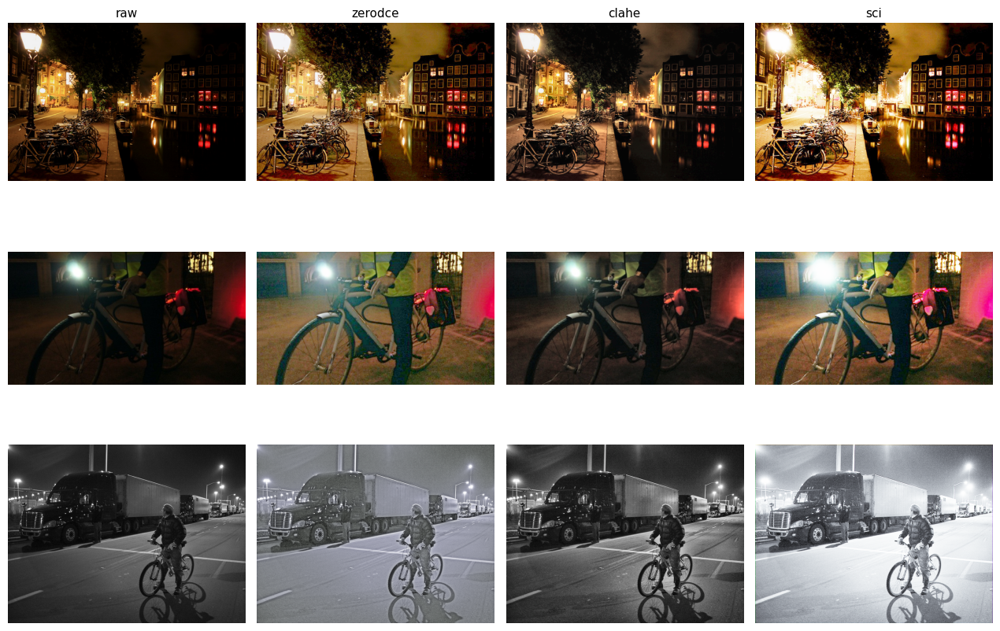

Mean luminance / contrast over 60 probe train images (0-255):
  raw      mean= 49.56   within-image std= 45.55
  zerodce  mean= 99.76   within-image std= 49.05
  clahe    mean= 65.53   within-image std= 51.70
  sci      mean=124.86   within-image std= 68.62


In [8]:
import matplotlib.pyplot as plt

_show = TRAIN[:3]
fig, axes = plt.subplots(len(_show), len(CFG.methods),
                         figsize=(3.2 * len(CFG.methods), 3.0 * len(_show)))
axes = np.atleast_2d(axes)
for r, s in enumerate(_show):
    for c, m in enumerate(CFG.methods):
        axes[r, c].imshow(Image.open(pool_path(s, m)).convert("RGB"))
        axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(m, fontsize=11)
plt.tight_layout()
os.makedirs(CFG.results_dir, exist_ok=True)
fig.savefig(os.path.join(CFG.results_dir, "enhancer_examples.png"), dpi=120, bbox_inches="tight")
plt.show()

print("Mean luminance / contrast over 60 probe train images (0-255):")
BRIGHT = {}
for m in CFG.methods:
    means, stds = [], []
    for s in TRAIN[:60]:
        a = np.asarray(Image.open(pool_path(s, m)).convert("L"), dtype=np.float32)
        means.append(a.mean()); stds.append(a.std())
    BRIGHT[m] = {"mean": float(np.mean(means)), "std_within_image": float(np.mean(stds))}
    print(f"  {m:<8} mean={BRIGHT[m]['mean']:6.2f}   within-image std={BRIGHT[m]['std_within_image']:6.2f}")

## 9. Materialise the four COCO datasets

Reuses Phase 1's COCO conventions exactly — flat `<Class>__<stem><ext>` filenames, 1-indexed category
ids, clipped `xywh` boxes — then normalises to the Roboflow layout RF-DETR expects (placeholder
category 0 + classes 1…12), matching Stage 2.

**Every condition gets identical boxes and identical image identities; only the pixels differ.** The
closing assertion enforces that: image counts, annotation counts, category-id sums and total box area
must match across all four conditions, so a confound is caught here rather than after 12 runs.

In [9]:
CLASS_TO_CATID  = {c: i + 1 for i, c in enumerate(CLASSES)}
COCO_CATEGORIES = ([{"id": 0, "name": "exdark", "supercategory": "none"}] +
                   [{"id": i + 1, "name": c, "supercategory": "exdark"}
                    for i, c in enumerate(CLASSES)])

def _xyxy_to_xywh_clipped(box, W, H):
    x1, y1, x2, y2 = box
    x1 = max(0.0, min(x1, W)); y1 = max(0.0, min(y1, H))
    x2 = max(0.0, min(x2, W)); y2 = max(0.0, min(y2, H))
    w = max(0.0, x2 - x1);     h = max(0.0, y2 - y1)
    return [round(x1, 2), round(y1, 2), round(w, 2), round(h, 2)], w * h

def coco_file_name(s, method):
    """Flat, collision-free name. Extension follows the pool the image comes from."""
    ext = (os.path.splitext(s["filename"])[1] if method == "raw" else
           POOL_EXT if method == "zerodce" else CFG.enh_ext)
    return f"{s['primary_class']}__{os.path.splitext(s['filename'])[0]}{ext}"

def make_coco(subset, method):
    images, annotations, aid = [], [], 1
    for iid, s in enumerate(subset, start=1):
        W, H = s["width"], s["height"]
        images.append({"id": iid, "file_name": coco_file_name(s, method),
                       "width": W, "height": H})
        for cls, box in s["gt"]:                      # human GT, identical across conditions
            cat = CLASS_TO_CATID.get(cls)
            if cat is None: continue
            bbox, area = _xyxy_to_xywh_clipped(box, W, H)
            if bbox[2] <= 1 or bbox[3] <= 1: continue
            annotations.append({"id": aid, "image_id": iid, "category_id": cat,
                                "bbox": bbox, "area": round(area, 2), "iscrowd": 0})
            aid += 1
    return {"images": images, "annotations": annotations, "categories": COCO_CATEGORIES}

def materialize(method, cfg=CFG):
    root = os.path.join(cfg.work_root, method)
    if os.path.isfile(os.path.join(root, "train", "_annotations.coco.json")):
        print(f"[dataset] {method}: already built"); return root
    split_dir = {"train": "train", "val": "valid", "test": "test"}
    summary = {}
    for split, subset in [("train", TRAIN), ("val", VAL), ("test", TEST)]:
        outdir = os.path.join(root, split_dir[split]); os.makedirs(outdir, exist_ok=True)
        coco = make_coco(subset, method)
        for s, im in zip(subset, coco["images"]):
            dst = os.path.join(outdir, im["file_name"])
            if not os.path.exists(dst):
                shutil.copy2(pool_path(s, method), dst)
        json.dump(coco, open(os.path.join(outdir, "_annotations.coco.json"), "w"))
        summary[split] = (len(coco["images"]), len(coco["annotations"]))
    print(f"[dataset] {method}: " + " | ".join(f"{k} {v[0]}img/{v[1]}box"
                                               for k, v in summary.items()))
    return root

os.makedirs(CFG.work_root, exist_ok=True)
DATASETS = {m: materialize(m) for m in CFG.methods}

# ── every referenced image file must exist on disk ──
for m, d in DATASETS.items():
    for split in ["train", "valid", "test"]:
        c = json.load(open(os.path.join(d, split, "_annotations.coco.json")))
        miss = [im["file_name"] for im in c["images"]
                if not os.path.isfile(os.path.join(d, split, im["file_name"]))]
        assert not miss, f"{m}/{split}: {len(miss)} images missing, e.g. {miss[0]}"
print("File-presence check: OK")

# ── verify the conditions are label-identical (only pixels should differ) ──
print("\nLabel-identity check (all conditions must agree exactly):")
ref = None
for m in CFG.methods:
    sig = []
    for split in ["train", "valid", "test"]:
        c = json.load(open(os.path.join(DATASETS[m], split, "_annotations.coco.json")))
        sig.append((len(c["images"]), len(c["annotations"]),
                    sum(a["category_id"] for a in c["annotations"]),
                    round(sum(a["bbox"][2] * a["bbox"][3] for a in c["annotations"]), 1)))
    print(f"  {m:<8}", sig)
    if ref is None: ref = sig
    else: assert sig == ref, f"{m} labels differ from {CFG.methods[0]} — conditions are confounded!"
print("OK — identical labels across all four conditions.")

[dataset] raw: train 480img/1680box | val 120img/371box | test 300img/888box
[dataset] zerodce: train 480img/1680box | val 120img/371box | test 300img/888box
[dataset] clahe: train 480img/1680box | val 120img/371box | test 300img/888box
[dataset] sci: train 480img/1680box | val 120img/371box | test 300img/888box
File-presence check: OK

Label-identity check (all conditions must agree exactly):
  raw      [(480, 1680, 12512, 102712629.0), (120, 371, 2948, 37014599.0), (300, 888, 6649, 99195539.0)]
  zerodce  [(480, 1680, 12512, 102712629.0), (120, 371, 2948, 37014599.0), (300, 888, 6649, 99195539.0)]
  clahe    [(480, 1680, 12512, 102712629.0), (120, 371, 2948, 37014599.0), (300, 888, 6649, 99195539.0)]
  sci      [(480, 1680, 12512, 102712629.0), (120, 371, 2948, 37014599.0), (300, 888, 6649, 99195539.0)]
OK — identical labels across all four conditions.


## 10. Train — 4 conditions x N seeds, fixed budget

`RFDETRSmall` (the 29M "Base"), same hyperparameters as Stage 2 apart from the shortened epoch
budget. Seeding is applied globally (init + shuffling) and, where the installed RF-DETR exposes a
`seed` argument, passed through explicitly. Each run checkpoints to Drive and is skipped once its
`.done` marker exists, so this cell can be re-run across sessions.

In [10]:
from rfdetr import RFDETRSmall

BEST_NAMES   = ["checkpoint_best_ema.pth", "checkpoint_best_total.pth", "checkpoint_best_regular.pth"]
RESUME_NAMES = ["last.ckpt", "checkpoint.pth", "checkpoint_best_total.pth",
                "checkpoint_best_ema.pth", "checkpoint_best_regular.pth"]

def _first_existing(out_dir, names):
    for n in names:
        p = os.path.join(out_dir, n)
        if os.path.isfile(p): return p
    hits = sorted(glob.glob(os.path.join(out_dir, "checkpoint_best*.pth")))
    return hits[0] if hits else None

def _set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def _accepts(fn, name):
    """True only if `name` is an explicit parameter (not swallowed by **kwargs)."""
    try:
        return name in inspect.signature(fn).parameters
    except (TypeError, ValueError):
        return False

def run_tag(method, seed): return f"{method}_s{seed}"

def train_run(method, seed, cfg=CFG):
    tag = run_tag(method, seed)
    out_dir = os.path.join(cfg.ckpt_root, tag); os.makedirs(out_dir, exist_ok=True)
    if os.path.isfile(os.path.join(out_dir, ".done")):
        print(f"[train] {tag}: complete — skipping.")
        return out_dir, _first_existing(out_dir, BEST_NAMES)

    _set_seed(seed)
    kwargs = dict(dataset_dir=DATASETS[method], epochs=cfg.epochs, batch_size=BATCH_SIZE,
                  grad_accum_steps=GRAD_ACCUM, lr=cfg.lr, output_dir=out_dir,
                  early_stopping=cfg.early_stopping, tensorboard=True)
    if cfg.resolution: kwargs["resolution"] = cfg.resolution
    model = RFDETRSmall()
    if _accepts(model.train, "seed"): kwargs["seed"] = seed

    resume = _first_existing(out_dir, RESUME_NAMES); t = time.time()
    try:
        if resume:
            print(f"[train] {tag}: resuming from {os.path.basename(resume)}")
            model.train(resume=resume, **kwargs)
        else:
            print(f"[train] {tag}: fresh ({cfg.epochs} epochs, seed={seed})")
            model.train(**kwargs)
    except Exception as e:
        if resume:
            print(f"[train] {tag}: resume failed ({type(e).__name__}); restarting fresh.")
            _set_seed(seed); RFDETRSmall().train(**kwargs)
        else:
            raise
    open(os.path.join(out_dir, ".done"), "w").write(f"{cfg.epochs}|seed={seed}")
    print(f"[train] {tag}: finished in {(time.time()-t)/60:.1f} min")
    return out_dir, _first_existing(out_dir, BEST_NAMES)

os.makedirs(CFG.ckpt_root, exist_ok=True)
RUNS = {}
for method in CFG.methods:
    for seed in CFG.seeds:
        out_dir, best = train_run(method, seed)
        RUNS[run_tag(method, seed)] = {"method": method, "seed": seed, "out_dir": out_dir,
                                       "best": best, "dataset": DATASETS[method]}

print("\nRun status:")
for tag, i in RUNS.items():
    print(f"  {tag:<14} done={os.path.isfile(os.path.join(i['out_dir'], '.done'))}  "
          f"best={os.path.basename(i['best']) if i['best'] else None}")

[train] raw_s0: complete — skipping.
[train] raw_s1: complete — skipping.
[train] raw_s2: complete — skipping.
[train] zerodce_s0: complete — skipping.
[train] zerodce_s1: complete — skipping.
[train] zerodce_s2: complete — skipping.
[train] clahe_s0: complete — skipping.
[train] clahe_s1: complete — skipping.
[train] clahe_s2: complete — skipping.
[train] sci_s0: complete — skipping.
[train] sci_s1: complete — skipping.
[train] sci_s2: complete — skipping.

Run status:
  raw_s0         done=True  best=checkpoint_best_ema.pth
  raw_s1         done=True  best=checkpoint_best_ema.pth
  raw_s2         done=True  best=checkpoint_best_ema.pth
  zerodce_s0     done=True  best=checkpoint_best_ema.pth
  zerodce_s1     done=True  best=checkpoint_best_ema.pth
  zerodce_s2     done=True  best=checkpoint_best_ema.pth
  clahe_s0       done=True  best=checkpoint_best_ema.pth
  clahe_s1       done=True  best=checkpoint_best_ema.pth
  clahe_s2       done=True  best=checkpoint_best_ema.pth
  sci_s0    

## 11. Evaluate — COCOeval on the probe test split

Identical evaluation code to Stage 2 (COCO-standard `maxDets=[1,10,100]`, AP read off the precision
tensor, class alignment resolved by name), so these numbers can be read next to the Stage 2 table.
Each condition is evaluated on **its own** enhanced test images — the deployment-realistic setting,
and the same convention Stage 2 used for Condition B.

Results are cached to Drive per run, so re-running this cell after a disconnect only evaluates what's
missing.

In [11]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import contextlib, io as _io

def _load_model(best):
    try: return RFDETRSmall.from_checkpoint(best)
    except Exception: return RFDETRSmall(pretrain_weights=best)

def _resolver(model, name_to_catid):
    names = getattr(model, "class_names", None)
    def r(cid, data):
        nm = None
        if isinstance(data, dict):
            a = data.get("class_name"); nm = a if isinstance(a, str) else None
        if nm is None and names is not None and 0 <= int(cid) < len(names): nm = names[int(cid)]
        if nm is not None:
            nm = str(nm)
            if nm in name_to_catid: return name_to_catid[nm]
            low = {k.lower(): v for k, v in name_to_catid.items()}
            if nm.lower() in low: return low[nm.lower()]
        if int(cid) in name_to_catid.values(): return int(cid)
        return int(cid) + 1
    return r

def evaluate_run(tag, best, dataset_dir, cfg=CFG):
    test_dir = os.path.join(dataset_dir, "test")
    coco_gt = COCO(os.path.join(test_dir, "_annotations.coco.json"))
    cats = coco_gt.loadCats(coco_gt.getCatIds())
    name_to_catid = {c["name"]: c["id"] for c in cats if c["name"] != "exdark"}
    fname_to_id = {coco_gt.loadImgs(i)[0]["file_name"]: i for i in coco_gt.getImgIds()}
    model = _load_model(best); resolve = _resolver(model, name_to_catid)
    results = []
    for fn, img_id in fname_to_id.items():
        p = os.path.join(test_dir, fn)
        if not os.path.isfile(p): continue
        det = model.predict(Image.open(p).convert("RGB"), threshold=cfg.eval_conf)
        xyxy = getattr(det, "xyxy", None); conf = getattr(det, "confidence", None)
        cid = getattr(det, "class_id", None); data = getattr(det, "data", {}) or {}
        n = 0 if xyxy is None else len(xyxy)
        order = np.argsort(-conf)[:cfg.max_detections] if (conf is not None and n) else range(n)
        for k in order:
            x1, y1, x2, y2 = [float(v) for v in xyxy[k]]
            cname = data.get("class_name")[k] if isinstance(data, dict) and "class_name" in data else None
            catid = resolve(int(cid[k]), {"class_name": cname} if cname is not None else {})
            results.append({"image_id": int(img_id), "category_id": int(catid),
                            "bbox": [x1, y1, x2 - x1, y2 - y1], "score": float(conf[k])})
    if not results:
        print(f"[eval] {tag}: no detections."); return None
    coco_dt = coco_gt.loadRes(results)
    ev = COCOeval(coco_gt, coco_dt, "bbox"); ev.params.maxDets = [1, 10, 100]
    with contextlib.redirect_stdout(_io.StringIO()):
        ev.evaluate(); ev.accumulate(); ev.summarize()
    prec = ev.eval["precision"]; iou = ev.params.iouThrs
    idx50 = int(np.argmin(np.abs(iou - 0.5)))
    id_to_name = {c["id"]: c["name"] for c in cats}
    per, per50, ap_all, ap50_all = {}, {}, [], []
    for k, cid_ in enumerate(coco_gt.getCatIds()):
        nm = id_to_name.get(cid_, str(cid_))
        if nm == "exdark": continue
        pr = prec[:, :, k, 0, -1]; pr = pr[pr > -1]
        ap = float(pr.mean()) if pr.size else float("nan")
        p50 = prec[idx50, :, k, 0, -1]; p50 = p50[p50 > -1]
        a50 = float(p50.mean()) if p50.size else float("nan")
        per[nm] = round(ap, 4); per50[nm] = round(a50, 4)
        if not np.isnan(ap): ap_all.append(ap)
        if not np.isnan(a50): ap50_all.append(a50)
    return {"mAP":   round(float(np.mean(ap_all)), 4)   if ap_all   else float("nan"),
            "mAP50": round(float(np.mean(ap50_all)), 4) if ap50_all else float("nan"),
            "per_class": per, "per_class_50": per50}

EVAL_CACHE = os.path.join(CFG.results_dir, "probe_eval_cache.json")
EVAL = json.load(open(EVAL_CACHE)) if os.path.isfile(EVAL_CACHE) else {}

for tag, info in RUNS.items():
    if tag in EVAL and EVAL[tag].get("metrics"):
        print(f"[eval] {tag}: cached"); continue
    if not info["best"]:
        print(f"[eval] {tag}: no checkpoint — skipping."); continue
    print(f"\n=== Evaluating {tag} ===")
    m = evaluate_run(tag, info["best"], info["dataset"])
    EVAL[tag] = {"method": info["method"], "seed": info["seed"], "metrics": m}
    json.dump(EVAL, open(EVAL_CACHE, "w"), indent=2)
    if m: print(f"  mAP@0.5={m['mAP50']}  mAP@[.5:.95]={m['mAP']}")

print("\nEvaluated runs:", len([t for t in EVAL if EVAL[t].get('metrics')]))

[eval] raw_s0: cached
[eval] raw_s1: cached
[eval] raw_s2: cached
[eval] zerodce_s0: cached
[eval] zerodce_s1: cached
[eval] zerodce_s2: cached
[eval] clahe_s0: cached
[eval] clahe_s1: cached
[eval] clahe_s2: cached
[eval] sci_s0: cached
[eval] sci_s1: cached
[eval] sci_s2: cached

Evaluated runs: 12


In [12]:
# --- diagnose the blank §11b output ---
print("TEST length      :", len(TEST))
print("VIZ_INDICES      :", VIZ_INDICES if "VIZ_INDICES" in globals() else "NOT DEFINED")
print("RUNS keys        :", list(RUNS)[:6], "..." if len(RUNS) > 6 else "")
print("methods          :", CFG.methods)

s = TEST[0]
print("\nsample[0]        :", s["primary_class"], s["filename"], "gt boxes:", len(s.get("gt", [])))
for m in CFG.methods:
    p = pool_path(s, m)
    print(f"  {m:<8} exists={os.path.isfile(p)}  {p}")
    info = RUNS.get(f"{m}_s{CFG.seeds[0]}")
    print(f"           run best = {info.get('best') if info else 'NO RUN'}")

# does predict actually return anything?
_m = _load_model(RUNS[f"{CFG.methods[0]}_s{CFG.seeds[0]}"]["best"])
_d = _m.predict(Image.open(pool_path(s, CFG.methods[0])).convert("RGB"), threshold=0.01)
print("\nraw predict xyxy :", getattr(_d, "xyxy", None) is not None,
      "n=", 0 if getattr(_d,"xyxy",None) is None else len(_d.xyxy))

TEST length      : 300
VIZ_INDICES      : NOT DEFINED
RUNS keys        : ['raw_s0', 'raw_s1', 'raw_s2', 'zerodce_s0', 'zerodce_s1', 'zerodce_s2'] ...
methods          : ('raw', 'zerodce', 'clahe', 'sci')

sample[0]        : Bicycle 2015_00547.jpg gt boxes: 4
  raw      exists=True  /content/probe_raw/Bicycle/2015_00547.jpg
           run best = /content/drive/MyDrive/ExDark_dataset/probe_enh_checkpoints/raw_s0/checkpoint_best_ema.pth
  zerodce  exists=True  /content/drive/MyDrive/ExDark_dataset/ExDark_enhanced/Bicycle/2015_00547.png
           run best = /content/drive/MyDrive/ExDark_dataset/probe_enh_checkpoints/zerodce_s0/checkpoint_best_ema.pth
  clahe    exists=True  /content/drive/MyDrive/ExDark_dataset/probe_enhanced/clahe/Bicycle/2015_00547.png
           run best = /content/drive/MyDrive/ExDark_dataset/probe_enh_checkpoints/clahe_s0/checkpoint_best_ema.pth
  sci      exists=True  /content/drive/MyDrive/ExDark_dataset/probe_enhanced/sci/Bicycle/2015_00547.png
           run best

/usr/local/lib/python3.12/dist-packages/rfdetr/detr.py:551: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.12/dist-packages/rfdetr/detr.py:551: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.12/dist-packages/rfdetr/detr.py:551: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-08-15 03:29:59] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-15 03:29:59] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is


raw predict xyxy : True n= 125


[viz] rendering 5 scenes x 4 conditions (seed 0, display threshold 0.3)
[viz] yellow dashed = human GT   |   solid coloured = model prediction


[2026-08-15 03:30:05] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-15 03:30:05] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-15 03:30:06] [WARNING] rf-detr - load_pretrain_weights: args.num_queries absent; inferred ckpt_num_queries=300 from tensor rows 3900 ÷ ckpt_group_detr=13.
[2026-08-15 03:30:06] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).
[2026-08-15 03:30:10] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetunin

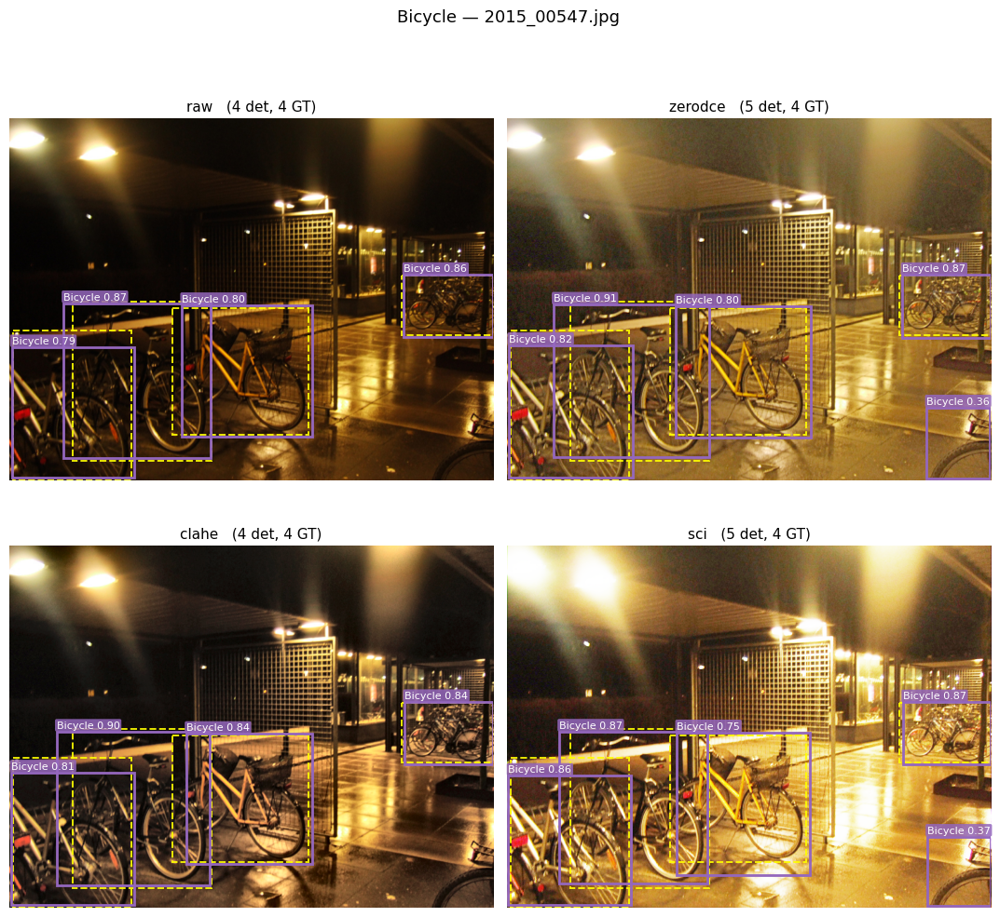

  2015_00547.jpg           detections per condition: raw=4, zerodce=5, clahe=4, sci=5   -> saved qual_Bicycle_2015_00547.png


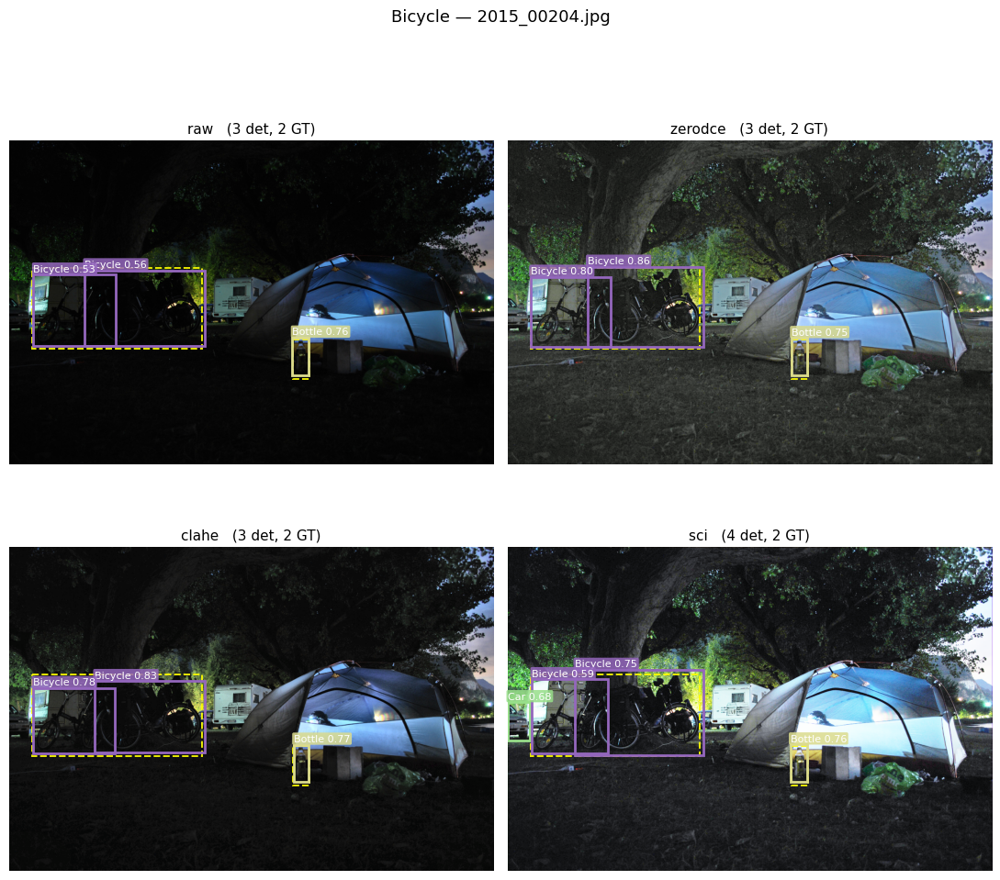

  2015_00204.jpg           detections per condition: raw=3, zerodce=3, clahe=3, sci=4   -> saved qual_Bicycle_2015_00204.png


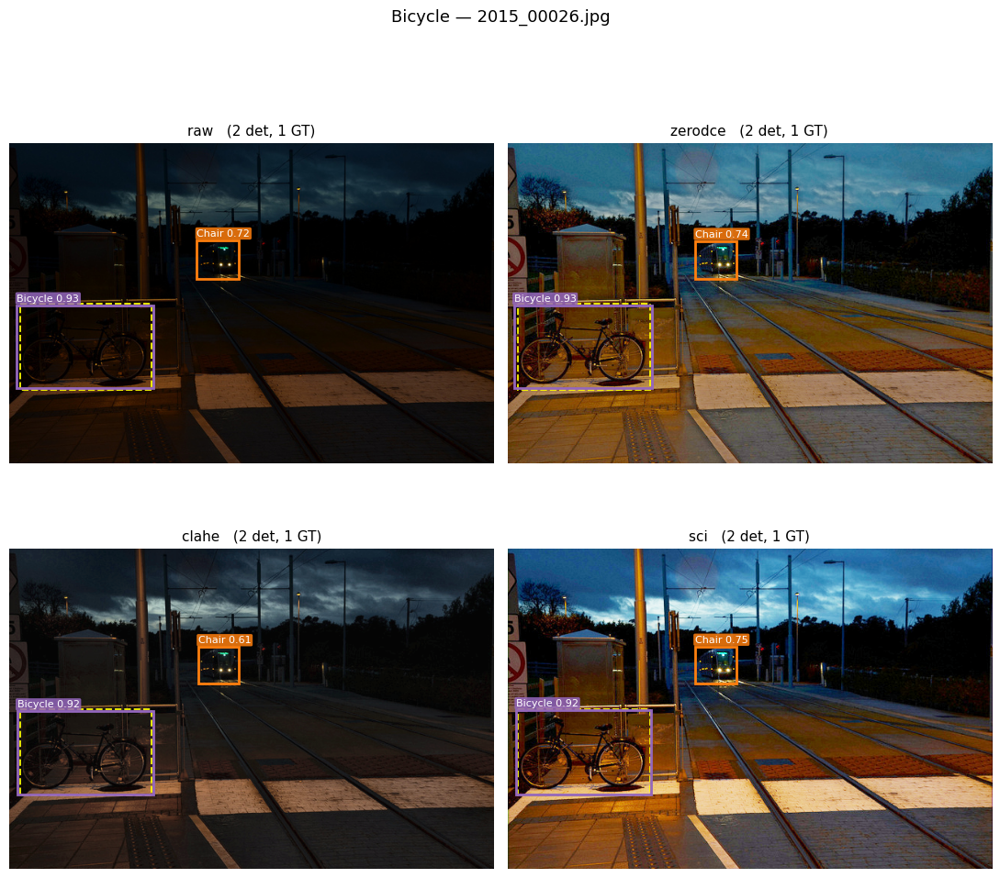

  2015_00026.jpg           detections per condition: raw=2, zerodce=2, clahe=2, sci=2   -> saved qual_Bicycle_2015_00026.png


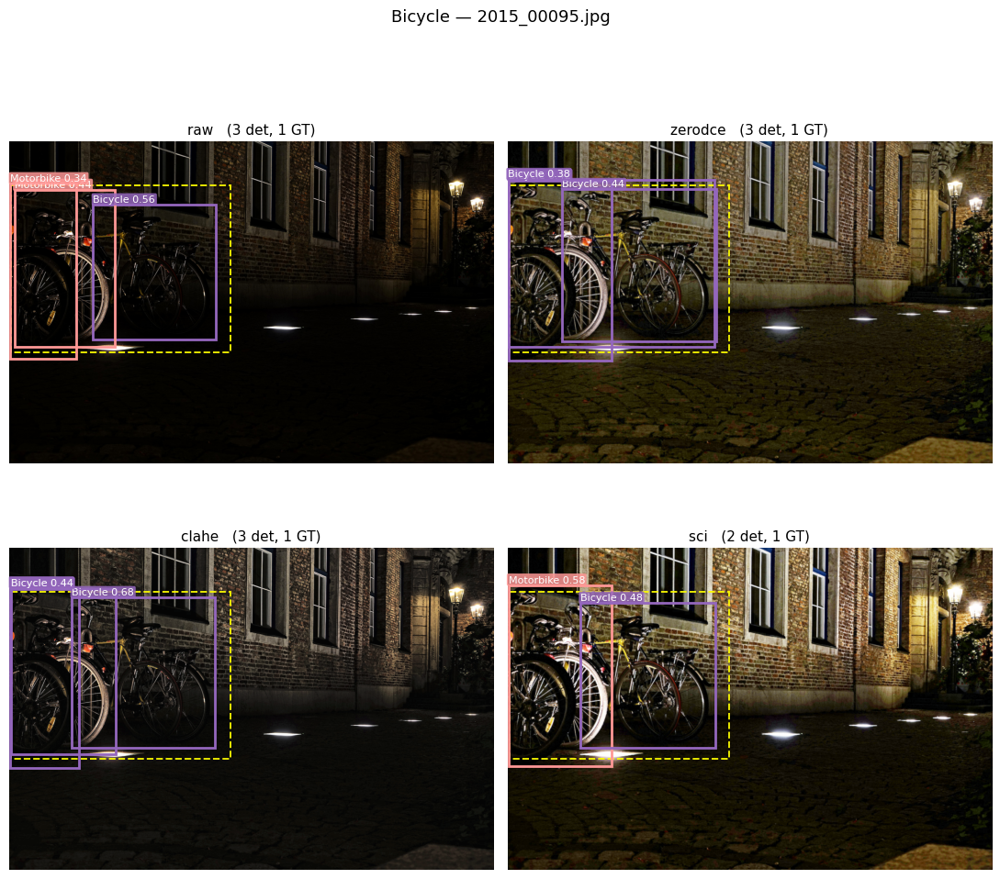

  2015_00095.jpg           detections per condition: raw=3, zerodce=3, clahe=3, sci=2   -> saved qual_Bicycle_2015_00095.png


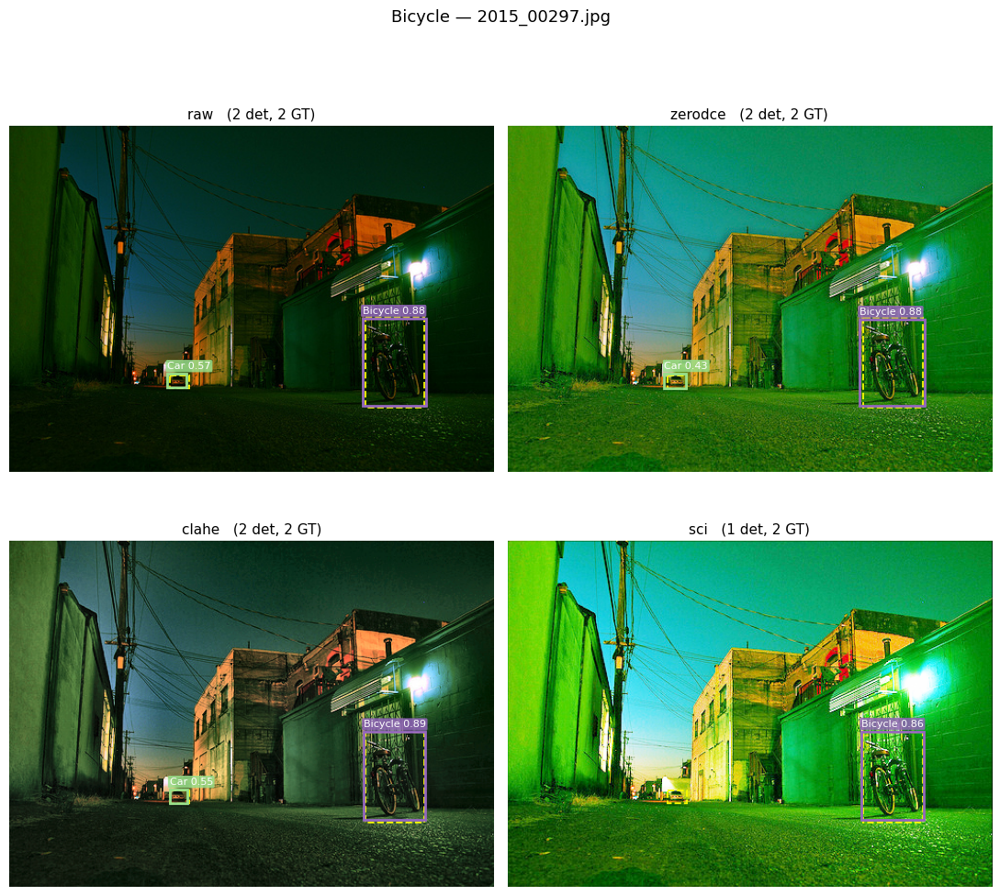

  2015_00297.jpg           detections per condition: raw=2, zerodce=2, clahe=2, sci=1   -> saved qual_Bicycle_2015_00297.png

[viz] figures saved under /content/drive/MyDrive/ExDark_dataset/probe_enh_results/qualitative


In [13]:
# =============================================================================
# §11b — Qualitative visualization: per-condition detections in a 2x2 grid.
# raw / zerodce / clahe / sci side by side, each with its own model's
# predictions on its own enhanced image. Select images via VIZ_INDICES.
# =============================================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── knobs ────────────────────────────────────────────────────────────────────
VIZ_SEED       = CFG.seeds[0]   # which trained seed's model to use per condition
VIZ_THRESHOLD  = 0.30       # confidence floor for *display* (higher than eval's 0.01)
VIZ_SHOW_GT    = True       # overlay human GT boxes (yellow, dashed)
VIZ_MAX_BOXES  = 20         # cap boxes drawn per panel
VIZ_INDICES    = [0, 1, 2, 3, 4]  # which TEST images to render, by index (0-based)

_PALETTE = plt.get_cmap("tab20").colors   # stable per-class colours

# ── model cache: load each condition's chosen checkpoint once ────────────────
if "_load_model" not in globals():
    def _load_model(best):
        try: return RFDETRSmall.from_checkpoint(best)
        except Exception: return RFDETRSmall(pretrain_weights=best)

_viz_models = {}
def _viz_model(method):
    if method in _viz_models:
        return _viz_models[method]
    tag = f"{method}_s{VIZ_SEED}"
    info = RUNS.get(tag)
    if not info or not info.get("best"):
        alt = next((v for k, v in RUNS.items()
                    if v["method"] == method and v.get("best")), None)
        if alt is None:
            print(f"[viz] no trained checkpoint for '{method}' — skipping panel.")
            _viz_models[method] = None
            return None
        info = alt
        print(f"[viz] {method}: seed {VIZ_SEED} unavailable, using {os.path.basename(info['out_dir'])}")
    _viz_models[method] = _load_model(info["best"])
    return _viz_models[method]

def _class_name(model, cid, data, k):
    if isinstance(data, dict) and "class_name" in data:
        try: return str(data["class_name"][k])
        except Exception: pass
    names = getattr(model, "class_names", None)
    if names is not None and 0 <= int(cid) < len(names):
        return str(names[int(cid)])
    return str(int(cid))

def _predict_boxes(model, pil_img):
    det = model.predict(pil_img, threshold=VIZ_THRESHOLD)
    xyxy = getattr(det, "xyxy", None)
    conf = getattr(det, "confidence", None)
    cid  = getattr(det, "class_id", None)
    data = getattr(det, "data", {}) or {}
    n = 0 if xyxy is None else len(xyxy)
    if not n:
        return []
    order = np.argsort(-conf)[:VIZ_MAX_BOXES] if conf is not None else range(min(n, VIZ_MAX_BOXES))
    out = []
    for k in order:
        x1, y1, x2, y2 = [float(v) for v in xyxy[k]]
        label = _class_name(model, cid[k] if cid is not None else -1, data, k)
        c = float(conf[k]) if conf is not None else float("nan")
        out.append((x1, y1, x2, y2, label, c))
    return out

def _draw(ax, pil_img, boxes, gt, title):
    ax.imshow(pil_img)
    ax.set_title(title, fontsize=11)
    ax.axis("off")
    if VIZ_SHOW_GT:
        for cls, (gx1, gy1, gx2, gy2) in gt:
            ax.add_patch(mpatches.Rectangle((gx1, gy1), gx2 - gx1, gy2 - gy1,
                         fill=False, edgecolor="yellow", linewidth=1.4,
                         linestyle="--", alpha=0.9))
    for (x1, y1, x2, y2, label, c) in boxes:
        col = _PALETTE[(hash(label) % len(_PALETTE))]
        ax.add_patch(mpatches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                     fill=False, edgecolor=col, linewidth=2.0))
        ax.text(x1, max(0, y1 - 3), f"{label} {c:.2f}", fontsize=8, color="white",
                va="bottom", ha="left",
                bbox=dict(boxstyle="round,pad=0.15", fc=col, ec="none", alpha=0.85))

# ── select the requested test scenes by index ────────────────────────────────
_bad = [i for i in VIZ_INDICES if not (0 <= i < len(TEST))]
if _bad:
    print(f"[viz] ignoring out-of-range indices {_bad} (TEST has {len(TEST)} images: 0..{len(TEST)-1})")
_show = [TEST[i] for i in VIZ_INDICES if 0 <= i < len(TEST)]
assert _show, f"No valid indices in VIZ_INDICES={VIZ_INDICES}; TEST has {len(TEST)} images."

print(f"[viz] rendering {len(_show)} scenes x {len(CFG.methods)} conditions "
      f"(seed {VIZ_SEED}, display threshold {VIZ_THRESHOLD})")
if VIZ_SHOW_GT:
    print("[viz] yellow dashed = human GT   |   solid coloured = model prediction")

_viz_dir = os.path.join(CFG.results_dir, "qualitative")
os.makedirs(_viz_dir, exist_ok=True)

for s in _show:
    ncol = 2
    nrow = int(np.ceil(len(CFG.methods) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(11, 5.2 * nrow))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    n_det = {}
    for ax, method in zip(axes, CFG.methods):
        img = Image.open(pool_path(s, method)).convert("RGB")
        model = _viz_model(method)
        if model is None:
            ax.imshow(img); ax.set_title(f"{method} (no model)", fontsize=11); ax.axis("off")
            continue
        boxes = _predict_boxes(model, img)
        n_det[method] = len(boxes)
        _draw(ax, img, boxes, s.get("gt", []),
              f"{method}   ({len(boxes)} det, {len(s.get('gt', []))} GT)")
    fig.suptitle(f"{s['primary_class']} — {s['filename']}", fontsize=13, y=0.995)
    fig.tight_layout(rect=[0, 0, 1, 0.98])
    out_png = os.path.join(_viz_dir, f"qual_{s['primary_class']}_{os.path.splitext(s['filename'])[0]}.png")
    fig.savefig(out_png, dpi=120, bbox_inches="tight")
    plt.show()
    print(f"  {s['filename']:<24} detections per condition: "
          + ", ".join(f"{m}={n_det.get(m,'-')}" for m in CFG.methods)
          + f"   -> saved {os.path.basename(out_png)}")

print(f"\n[viz] figures saved under {_viz_dir}")

[quant] scanning 300 images x 3 enhancers (conf>=0.3, GT IoU<0.3, cluster IoU>=0.5)


[2026-08-15 03:30:38] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-15 03:30:38] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-15 03:30:39] [WARNING] rf-detr - load_pretrain_weights: args.num_queries absent; inferred ckpt_num_queries=300 from tensor rows 3900 ÷ ckpt_group_detr=13.


quant-scan:   0%|          | 0/300 [00:00<?, ?it/s]

[2026-08-15 03:30:39] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).
[2026-08-15 03:30:40] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-15 03:30:40] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-15 03:30:41] [WARNING] rf-detr - load_pretrain_weights: args.num_queries absent; inferred ckpt_num_queries=300 from tensor rows 3900 ÷ ckpt_group_detr=13.
[2026-08-15 03:30:41] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.i

[quant] 281 distinct surfaced objects (GT-unmatched clusters)
[class] detector emitted 11 distinct class names; unrecognised vs CLASSES: none
[class] detected class equals the image's filed category for 90/281 surfaced objects (32.0%). The two are different quantities, which is why the figure prints both.
[class] all firing methods agreed on the class for 273/281 (97.2%).

=== Surfaced objects by consensus x confidence (count) ===


,0.30-0.50,0.50-0.70,0.70-0.90,0.90-1.00,TOTAL
1/3 methods,126,12,1,0,139
2/3 methods,38,15,4,0,57
3/3 methods,21,41,22,1,85
TOTAL,185,68,27,1,281


(of which RAW-MISSED — the true rescues raw's own model also failed to find:)


,0.30-0.50,0.50-0.70,0.70-0.90,0.90-1.00
1/3 methods,93,7,0,0
2/3 methods,19,3,0,0
3/3 methods,6,5,0,0


Single-method (1/3) objects by enhancer: zerodce=48, clahe=45, sci=46


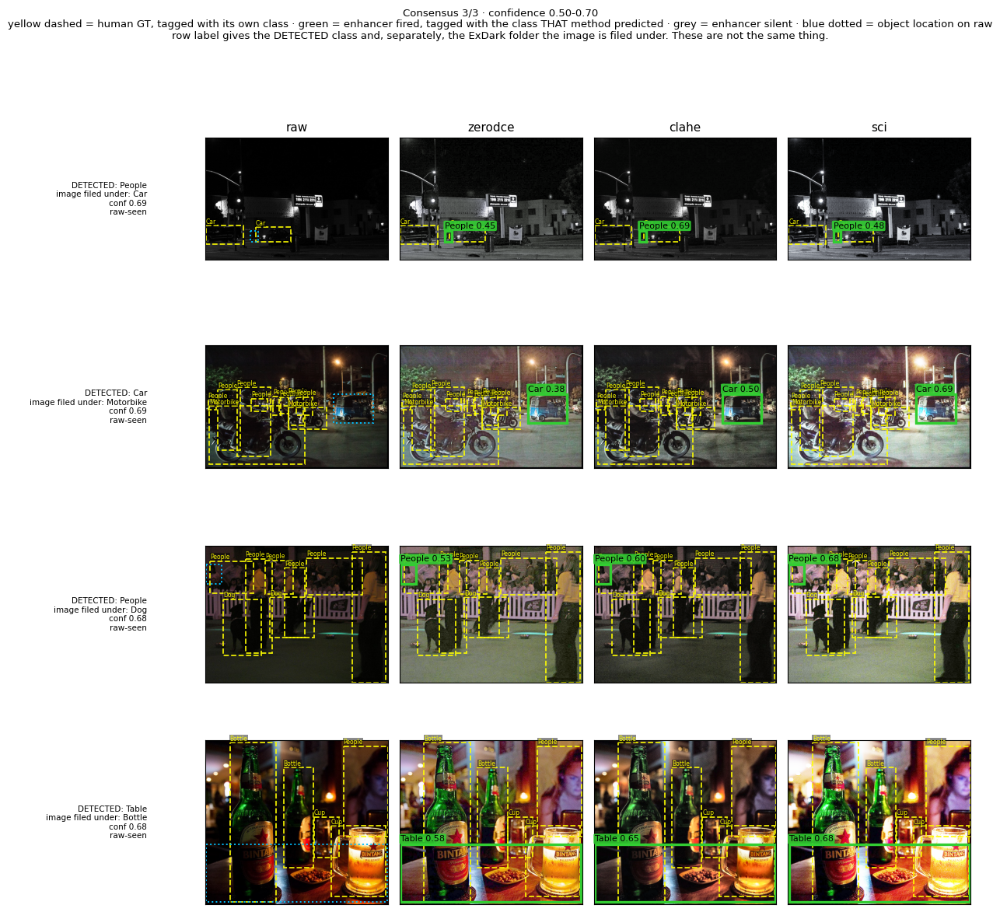

  saved examples_c3_conf_050-070.png  (4 full-image examples)


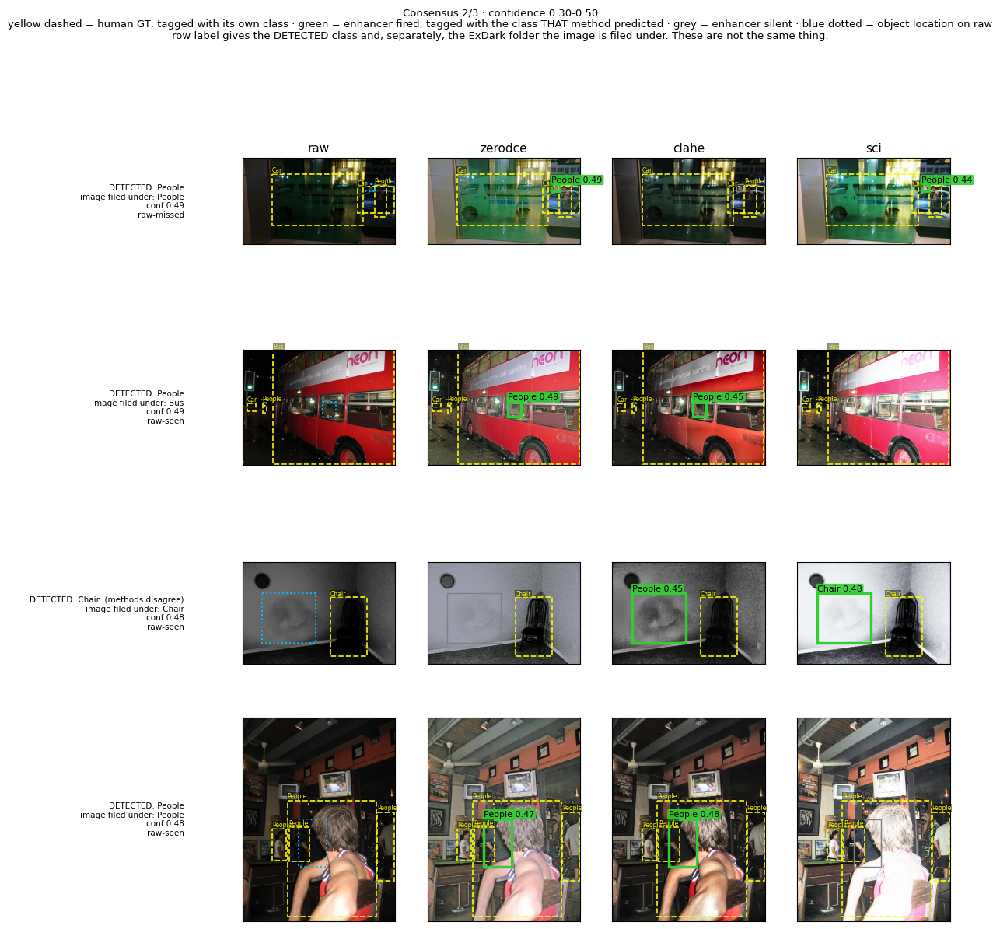

  saved examples_c2_conf_030-050.png  (4 full-image examples)


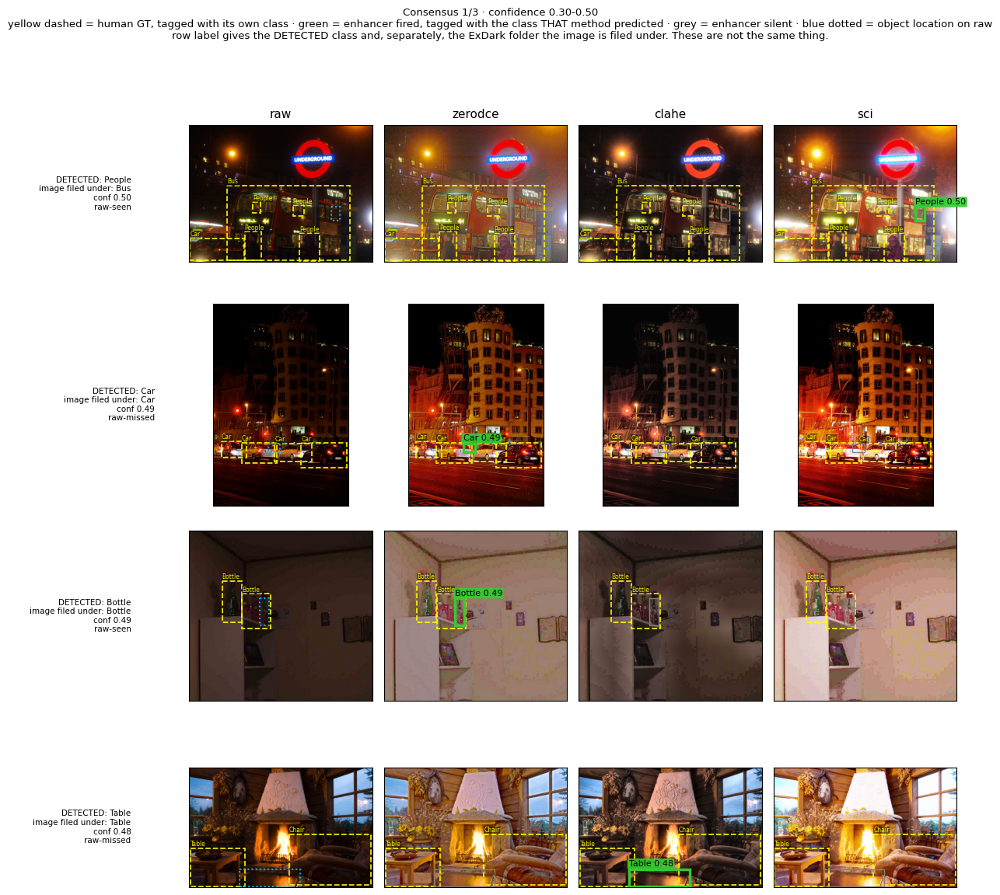

  saved examples_c1_conf_030-050.png  (4 full-image examples)

[quant] table + per-cluster CSV + example figures under /content/drive/MyDrive/ExDark_dataset/probe_enh_results


In [14]:
# =============================================================================
# §11d — Quantify enhancement-surfaced detections by CONFIDENCE x CONSENSUS.
# A "candidate" = a confident detection from an enhancer that no human GT box
# covers. Candidates pointing at the same region across enhancers are clustered;
# a cluster's CONSENSUS = how many of the 3 enhancers surfaced it (1/3..3/3).
# Outputs: a count table (consensus x confidence bucket) + example crop strips
# (raw|zerodce|clahe|sci) for the key groups. Needs RUNS, pool_path, TEST, CFG.
# =============================================================================
import matplotlib.pyplot as plt
import pandas as pd

# ── knobs ────────────────────────────────────────────────────────────────────
Q_ENH_METHODS  = [m for m in CFG.methods if m != "raw"]   # the enhancers to pool
Q_CONF_MIN     = 0.30    # scan threshold (also the lowest bucket edge)
Q_CONF_EDGES   = [0.30, 0.50, 0.70, 0.90, 1.01]           # confidence buckets
Q_GT_IOU       = 0.30    # det with max IoU<this vs GT is "not in the labels"
Q_CLUSTER_IOU  = 0.50    # dets overlapping >=this (across methods) are one object
Q_RAW_IOU      = 0.30    # cluster is "raw-missed" if raw's dets stay below this
Q_MAX_IMAGES   = None    # cap images scanned (None = all)
Q_EX_PER_GROUP = 4       # example strips to render per key group
Q_PAD_FRAC     = 0.30    # context padding around each crop
Q_TILE_H       = 120     # px height per crop
Q_SEED         = CFG.seeds[0]
Q_SHOW_GT_LAB  = True    # print each GT box's own class next to it (proves multi-class labels)

_BUCKETS = [(Q_CONF_EDGES[i], Q_CONF_EDGES[i+1],
             f"{Q_CONF_EDGES[i]:.2f}-{Q_CONF_EDGES[i+1] if Q_CONF_EDGES[i+1]<=1 else 1.0:.2f}")
            for i in range(len(Q_CONF_EDGES)-1)]
def _bucket(conf):
    for lo, hi, lab in _BUCKETS:
        if lo <= conf < hi: return lab
    return _BUCKETS[-1][2]

# ── model cache (reuse §11b/§11c if present) ─────────────────────────────────
if "_load_model" not in globals():
    def _load_model(best):
        try: return RFDETRSmall.from_checkpoint(best)
        except Exception: return RFDETRSmall(pretrain_weights=best)
if "_viz_models" not in globals():
    _viz_models = {}
def _q_model(method):
    key = f"{method}_s{Q_SEED}"
    if key in _viz_models: return _viz_models[key]
    info = RUNS.get(key) or next((v for k, v in RUNS.items()
                                  if v["method"] == method and v.get("best")), None)
    _viz_models[key] = _load_model(info["best"]) if info and info.get("best") else None
    return _viz_models[key]

def _q_dets(model, img, thr):
    det = model.predict(img, threshold=thr)
    xyxy = getattr(det, "xyxy", None); conf = getattr(det, "confidence", None)
    cid  = getattr(det, "class_id", None); data = getattr(det, "data", {}) or {}
    names = getattr(model, "class_names", None)
    out = []
    for k in range(0 if xyxy is None else len(xyxy)):
        if conf is not None and float(conf[k]) < thr: continue
        x1, y1, x2, y2 = [float(v) for v in xyxy[k]]
        lab = None
        if isinstance(data, dict) and "class_name" in data:
            try: lab = str(data["class_name"][k])
            except Exception: lab = None
        if lab is None and names is not None and cid is not None and 0 <= int(cid[k]) < len(names):
            lab = str(names[int(cid[k])])
        out.append((x1, y1, x2, y2, lab or "?", float(conf[k]) if conf is not None else float("nan")))
    return out

def _iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    if inter <= 0: return 0.0
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / ua if ua > 0 else 0.0
def _max_iou(box, boxes): return max((_iou(box, b) for b in boxes), default=0.0)

# ── scan + cluster across enhancers ──────────────────────────────────────────
_scan = TEST if Q_MAX_IMAGES is None else TEST[:Q_MAX_IMAGES]
print(f"[quant] scanning {len(_scan)} images x {len(Q_ENH_METHODS)} enhancers "
      f"(conf>={Q_CONF_MIN}, GT IoU<{Q_GT_IOU}, cluster IoU>={Q_CLUSTER_IOU})")

_raw_model = _q_model("raw")
clusters = []   # each: dict(image, box, rep_conf, methods{}, raw_missed, primary_class)
for s in tqdm(_scan, desc="quant-scan"):
    gt_boxes = [b for _, b in s.get("gt", [])]
    raw_boxes = [d[:4] for d in _q_dets(_raw_model, Image.open(pool_path(s, "raw")).convert("RGB"),
                                        Q_CONF_MIN)] if _raw_model is not None else []
    # gather GT-unmatched confident dets from every enhancer
    dets = []
    for method in Q_ENH_METHODS:
        model = _q_model(method)
        if model is None: continue
        for d in _q_dets(model, Image.open(pool_path(s, method)).convert("RGB"), Q_CONF_MIN):
            box = d[:4]
            if _max_iou(box, gt_boxes) < Q_GT_IOU:     # not in the labels
                dets.append({"box": box, "conf": d[5], "label": d[4], "method": method})
    # greedy cluster by IoU, highest-confidence det seeds each cluster
    local = []
    for d in sorted(dets, key=lambda x: -x["conf"]):
        hit = next((c for c in local if _iou(d["box"], c["box"]) >= Q_CLUSTER_IOU), None)
        if hit is None:
            local.append({"image": s["filename"], "primary_class": s["primary_class"],
                          "box": d["box"], "rep_conf": d["conf"],
                          "methods": {d["method"]: d["conf"]},
                          "labels":  {d["method"]: d["label"]}})
        else:
            m_, cf_ = d["method"], d["conf"]
            if cf_ > hit["methods"].get(m_, -1.0):     # keep conf and class in step
                hit["methods"][m_] = cf_
                hit["labels"][m_]  = d["label"]
    for c in local:
        c["consensus"] = len(c["methods"])
        # The representative detection is the highest-confidence one in the cluster.
        # Its class is what the figure and the true per-class table report. This is a
        # different quantity from c["primary_class"], which is only the ExDark folder
        # the source image sits in.
        _top = max(c["methods"], key=lambda m: c["methods"][m])
        c["rep_conf"]    = c["methods"][_top]
        c["det_class"]   = c["labels"][_top]
        c["det_method"]  = _top
        c["class_agree"] = len(set(c["labels"].values())) == 1
        c["class_votes"] = " ".join("%s:%s" % (m, c["labels"][m]) for m in sorted(c["labels"]))
        c["raw_missed"] = _max_iou(c["box"], raw_boxes) < Q_RAW_IOU
        c["bucket"] = _bucket(c["rep_conf"])
    clusters.extend(local)

n = len(clusters)
print(f"[quant] {n} distinct surfaced objects (GT-unmatched clusters)")

# --- sanity: does the detector's class vocabulary line up with ExDark's? -------
_det_vocab = {c["det_class"] for c in clusters}
_unknown   = sorted(_det_vocab - set(CLASSES))
print(f"[class] detector emitted {len(_det_vocab)} distinct class names; "
      f"unrecognised vs CLASSES: {_unknown if _unknown else 'none'}")
if clusters:
    _same  = sum(1 for c in clusters if c["det_class"] == c["primary_class"])
    _agree = sum(1 for c in clusters if c["class_agree"])
    print(f"[class] detected class equals the image's filed category for "
          f"{_same}/{len(clusters)} surfaced objects ({100.0*_same/len(clusters):.1f}%). "
          f"The two are different quantities, which is why the figure prints both.")
    print(f"[class] all firing methods agreed on the class for {_agree}/{len(clusters)} "
          f"({100.0*_agree/len(clusters):.1f}%).")
if n == 0:
    print("[quant] nothing found — lower Q_CONF_MIN and rerun.")

# ── count table: consensus (rows) x confidence bucket (cols) ─────────────────
bucket_labels = [b[2] for b in _BUCKETS]
tbl = pd.DataFrame(0, index=[1, 2, 3], columns=bucket_labels)
tbl_rawmiss = pd.DataFrame(0, index=[1, 2, 3], columns=bucket_labels)
for c in clusters:
    tbl.loc[c["consensus"], c["bucket"]] += 1
    if c["raw_missed"]:
        tbl_rawmiss.loc[c["consensus"], c["bucket"]] += 1
tbl.index = [f"{k}/3 methods" for k in tbl.index]
tbl_rawmiss.index = tbl.index
tbl["TOTAL"] = tbl.sum(axis=1); tbl.loc["TOTAL"] = tbl.sum(axis=0)

print("\n=== Surfaced objects by consensus x confidence (count) ===")
display(tbl)
print("(of which RAW-MISSED — the true rescues raw's own model also failed to find:)")
display(tbl_rawmiss)

# single-method breakdown: which enhancer uniquely surfaces objects?
solo = Counter()
for c in clusters:
    if c["consensus"] == 1:
        solo[next(iter(c["methods"]))] += 1
print("Single-method (1/3) objects by enhancer:",
      ", ".join(f"{m}={solo.get(m,0)}" for m in Q_ENH_METHODS))

# ── visualize key groups (FULL IMAGE + boxes) ────────────────────────────────
import matplotlib.patches as mpatches

# key groups: for each consensus level, show its most-populated confidence bucket
# (single-method rescues are often not high-confidence, so don't assume the top bucket).
def _top_bucket(cons):
    cnt = Counter(c["bucket"] for c in clusters if c["consensus"] == cons)
    return cnt.most_common(1)[0][0] if cnt else None
KEY_GROUPS = [(cons, _top_bucket(cons)) for cons in (3, 2, 1) if _top_bucket(cons)]
_panel_methods = ["raw"] + Q_ENH_METHODS
_qdir = os.path.join(CFG.results_dir, "quant_examples")
os.makedirs(_qdir, exist_ok=True)

def _draw_full(ax, img, s, cluster, method):
    """Full frame: GT (yellow dashed) + this cluster's surfaced box, highlighted
    if THIS method fired here. Other clusters in the frame drawn faint for context."""
    ax.imshow(img); ax.set_xticks([]); ax.set_yticks([])
    # human GT, each tagged with the class the annotator actually assigned it
    for _gcls, (gx1, gy1, gx2, gy2) in s.get("gt", []):
        ax.add_patch(mpatches.Rectangle((gx1, gy1), gx2-gx1, gy2-gy1, fill=False,
                     edgecolor="yellow", linewidth=1.3, linestyle="--", alpha=0.9))
        if Q_SHOW_GT_LAB:
            ax.text(gx1, max(0, gy1-2), str(_gcls), fontsize=5.5, color="yellow",
                    va="bottom", ha="left", alpha=0.95,
                    bbox=dict(boxstyle="square,pad=0.05", fc="black", ec="none", alpha=0.45))
    # the surfaced object under review
    x1, y1, x2, y2 = cluster["box"]
    fired = method in cluster["methods"]
    if method == "raw":
        col, lw, style = ("deepskyblue", 1.6, "-")   # raw never "fires" a surfaced box; ref only
        show = False
    else:
        col, lw, style = ("limegreen" if fired else "0.5", 2.4 if fired else 1.0, "-")
        show = True
    if show:
        ax.add_patch(mpatches.Rectangle((x1, y1), x2-x1, y2-y1, fill=False,
                     edgecolor=col, linewidth=lw, linestyle=style))
        if fired:
            conf = cluster["methods"][method]
            _lab = cluster["labels"].get(method, "?")
            ax.text(x1, max(0, y1-4), f"{_lab} {conf:.2f}", fontsize=8, color="black",
                    va="bottom", ha="left",
                    bbox=dict(boxstyle="round,pad=0.15", fc="limegreen", ec="none", alpha=0.9))
    else:
        # on the raw panel, mark WHERE the surfaced object is so the eye can compare
        ax.add_patch(mpatches.Rectangle((x1, y1), x2-x1, y2-y1, fill=False,
                     edgecolor="deepskyblue", linewidth=1.4, linestyle=":"))

for cons, buck in KEY_GROUPS:
    grp = sorted([c for c in clusters if c["consensus"] == cons and c["bucket"] == buck],
                 key=lambda c: -c["rep_conf"])[:Q_EX_PER_GROUP]
    if not grp:
        print(f"[quant] group {cons}/3 @ conf {buck}: no examples."); continue
    fig, axes = plt.subplots(len(grp), len(_panel_methods),
                             figsize=(len(_panel_methods)*3.1, len(grp)*3.0))
    axes = np.array(axes).reshape(len(grp), len(_panel_methods))
    for r, c in enumerate(grp):
        s_ = next(x for x in TEST if x["filename"] == c["image"])
        for cc, method in enumerate(_panel_methods):
            ax = axes[r, cc]
            img = Image.open(pool_path(s_, method)).convert("RGB")
            _draw_full(ax, img, s_, c, method)
            if r == 0: ax.set_title(method, fontsize=11)
            if cc == 0:
                _flag = "" if c["class_agree"] else "  (methods disagree)"
                ax.set_ylabel(f'DETECTED: {c["det_class"]}{_flag}'
                              f'\nimage filed under: {c["primary_class"]}'
                              f'\nconf {c["rep_conf"]:.2f}'
                              f'\n{"raw-missed" if c["raw_missed"] else "raw-seen"}',
                              fontsize=7.5, rotation=0, ha="right", va="center", labelpad=54)
    fig.suptitle(f"Consensus {cons}/3 · confidence {buck}\n"
                 f"yellow dashed = human GT, tagged with its own class · "
                 f"green = enhancer fired, tagged with the class THAT method predicted · "
                 f"grey = enhancer silent · blue dotted = object location on raw\n"
                 f"row label gives the DETECTED class and, separately, the ExDark folder the "
                 f"image is filed under. These are not the same thing.",
                 fontsize=9.5, y=1.0)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    out = os.path.join(_qdir, f"examples_c{cons}_conf_{buck.replace('.','')}.png")
    fig.savefig(out, dpi=130, bbox_inches="tight"); plt.show()
    print(f"  saved {os.path.basename(out)}  ({len(grp)} full-image examples)")

# ── persist ──────────────────────────────────────────────────────────────────
tbl.to_csv(os.path.join(CFG.results_dir, "quant_consensus_confidence.csv"))
if clusters:
    pd.DataFrame([{"image": c["image"], "primary_class": c["primary_class"],
                   "det_class": c["det_class"], "class_agree": c["class_agree"],
                   "class_votes": c["class_votes"],
                   "consensus": c["consensus"], "rep_conf": round(c["rep_conf"], 4),
                   "bucket": c["bucket"], "raw_missed": c["raw_missed"],
                   "methods": "+".join(sorted(c["methods"])),
                   "box": [round(v, 1) for v in c["box"]], "verdict": ""}
                  for c in sorted(clusters, key=lambda c: (-c["consensus"], -c["rep_conf"]))]
                 ).to_csv(os.path.join(CFG.results_dir, "quant_clusters.csv"), index=False)
print(f"\n[quant] table + per-cluster CSV + example figures under {CFG.results_dir}")

In [15]:
# ── significance: surfaced boxes relative to the existing GT box count ────────
gt_total = sum(len(s.get("gt", [])) for s in _scan)
n_rawmiss = sum(1 for c in clusters if c["raw_missed"])
def _pct(x, base): return f"{100.0*x/base:.1f}%" if base else "n/a"
print("\n=== Significance vs ground truth ===")
print(f"  GT boxes in scanned split      : {gt_total}")
print(f"  Surfaced objects (all)         : {n:>5}  ({_pct(n, gt_total)} of GT)")
print(f"  Surfaced & raw-missed (rescues): {n_rawmiss:>5}  ({_pct(n_rawmiss, gt_total)} of GT)")
for k in (3, 2, 1):
    ck = sum(1 for c in clusters if c["consensus"] == k)
    ckr = sum(1 for c in clusters if c["consensus"] == k and c["raw_missed"])
    print(f"    consensus {k}/3               : {ck:>5}  ({_pct(ck, gt_total)} of GT)"
          f"   | raw-missed {ckr} ({_pct(ckr, gt_total)})")
# -- where is the GT most incomplete? Two DIFFERENT groupings, reported separately --
#
# (a) TRUE PER-CLASS. Each GT box counted under the class the annotator gave it, and
#     each surfaced object under the class the detector assigned it. This answers
#     "which object classes go unlabelled".
# (b) BY SCENE TYPE. Every box in an image attributed to the ExDark folder that image
#     is filed under. ExDark images carry boxes for several classes at once, so this
#     is NOT a per-class view. It answers "which kinds of scene are labelled least
#     completely". Retained because earlier reporting used this grouping.

def _ratio_table(gt_counter, surf_counter, key_name):
    rows = []
    for k in sorted(set(gt_counter) | set(surf_counter),
                    key=lambda x: -(surf_counter.get(x, 0) / max(1, gt_counter.get(x, 0)))):
        g, su = gt_counter.get(k, 0), surf_counter.get(k, 0)
        rows.append({key_name: k, "GT_boxes": g, "surfaced": su,
                     "surfaced_%_of_GT": round(100.0 * su / g, 1) if g else None})
    return pd.DataFrame(rows).set_index(key_name)

gt_by_cls   = Counter(cls for s in _scan for cls, _ in s.get("gt", []))
surf_by_cls = Counter(c["det_class"] for c in clusters)
PERCLASS_TRUE = _ratio_table(gt_by_cls, surf_by_cls, "class")
print("\n  (a) TRUE per-class: GT boxes by their own class, surfaced objects by "
      "detected class (highest ratio first):")
display(PERCLASS_TRUE)

gt_by_img   = Counter(s["primary_class"] for s in _scan for _ in s.get("gt", []))
surf_by_img = Counter(c["primary_class"] for c in clusters)
PERCLASS_SCENE = _ratio_table(gt_by_img, surf_by_img, "image_category")
print("\n  (b) By SCENE TYPE: every box in an image attributed to that image's ExDark "
      "folder. Not a per-class view.")
display(PERCLASS_SCENE)

PERCLASS_TRUE.to_csv(os.path.join(CFG.results_dir, "surfaced_per_class_true.csv"))
PERCLASS_SCENE.to_csv(os.path.join(CFG.results_dir, "surfaced_per_scene_type.csv"))

# How far apart are the two groupings? If ExDark labelled only the filed class, the
# GT counts would be identical and every difference below would be zero.
_keys  = sorted(set(gt_by_cls) | set(gt_by_img))
_delta = pd.DataFrame({
    "GT_by_own_class":     [gt_by_cls.get(k, 0) for k in _keys],
    "GT_by_image_folder":  [gt_by_img.get(k, 0) for k in _keys],
}, index=_keys)
_delta["difference"] = _delta["GT_by_own_class"] - _delta["GT_by_image_folder"]
print("\n  GT counts under the two groupings. All-zero differences would mean ExDark "
      "labels only the filed class; it does not.")
display(_delta)


=== Significance vs ground truth ===
  GT boxes in scanned split      : 888
  Surfaced objects (all)         :   281  (31.6% of GT)
  Surfaced & raw-missed (rescues):   133  (15.0% of GT)
    consensus 3/3               :    85  (9.6% of GT)   | raw-missed 11 (1.2%)
    consensus 2/3               :    57  (6.4% of GT)   | raw-missed 22 (2.5%)
    consensus 1/3               :   139  (15.7% of GT)   | raw-missed 100 (11.3%)

  (a) TRUE per-class: GT boxes by their own class, surfaced objects by detected class (highest ratio first):


,GT_boxes,surfaced,surfaced_%_of_GT
class,,,
Table,61,38,62.3
People,244,95,38.9
Boat,55,20,36.4
Car,100,36,36.0
Cup,78,28,35.9
Motorbike,36,10,27.8
Cat,39,9,23.1
Bottle,59,13,22.0
Chair,111,23,20.7



  (b) By SCENE TYPE: every box in an image attributed to that image's ExDark folder. Not a per-class view.


,GT_boxes,surfaced,surfaced_%_of_GT
image_category,,,
Bus,71,38,53.5
Boat,69,34,49.3
Cup,59,21,35.6
Chair,83,29,34.9
Dog,41,13,31.7
Motorbike,109,34,31.2
People,81,25,30.9
Bicycle,57,15,26.3
Bottle,114,30,26.3



  GT counts under the two groupings. All-zero differences would mean ExDark labels only the filed class; it does not.


,GT_by_own_class,GT_by_image_folder,difference
Bicycle,43,57,-14
Boat,55,69,-14
Bottle,59,114,-55
Bus,30,71,-41
Car,100,63,37
Cat,39,44,-5
Chair,111,83,28
Cup,78,59,19
Dog,32,41,-9
Motorbike,36,109,-73


## 12. Aggregate across seeds & apply the noise-aware decision gate

This is the part Stage 2's Gate 1 could not do. For each candidate versus `raw`:

- **Δ** = mean(candidate) − mean(raw), averaged over seeds
- **pooled σ** = √((σ²_cand + σ²_raw)/2) — the empirical noise floor
- **verdict**: `WINS` only when Δ > `win_sigma` × pooled σ; `HURTS` when Δ < −`win_sigma` × pooled σ;
  otherwise **within noise** — which, note, is *not* the same claim as "no effect". It means this
  probe was not powerful enough to resolve one, and the effect (if any) is smaller than σ.

`|Δ|/σ` is reported as an effect size so a near-miss is visible rather than binarised away. The
per-seed spread printed under the noise floor is the number to quote when re-reading Stage 2's
`+0.0003`.

In [16]:
import pandas as pd

def collect(metric="mAP"):
    by = {m: [] for m in CFG.methods}
    for tag, e in EVAL.items():
        mt = e.get("metrics")
        if mt and e["method"] in by and not np.isnan(mt.get(metric, float("nan"))):
            by[e["method"]].append(mt[metric])
    return {k: np.array(v, dtype=float) for k, v in by.items() if len(v)}

STATS = {}
for metric in ["mAP", "mAP50"]:
    by = collect(metric)
    STATS[metric] = {m: {"n": int(v.size), "mean": float(v.mean()),
                         "std": float(v.std(ddof=1)) if v.size > 1 else float("nan"),
                         "runs": [round(float(x), 4) for x in v]}
                     for m, v in by.items()}

rows = []
for m in CFG.methods:
    a = STATS["mAP"].get(m); b = STATS["mAP50"].get(m)
    if not a: continue
    rows.append({"Condition": m, "seeds": a["n"],
                 "mAP@[.5:.95] mean": round(a["mean"], 4),
                 "± std": round(a["std"], 4) if a["n"] > 1 else None,
                 "per-seed": a["runs"],
                 "mAP@0.5 mean": round(b["mean"], 4) if b else None,
                 "tightness": round(a["mean"] / b["mean"], 3) if b and b["mean"] else None})
SUMMARY = pd.DataFrame(rows).sort_values("mAP@[.5:.95] mean", ascending=False)
print("=== Probe results (ExDark probe test split, human labels) ===")
display(SUMMARY)

# ── noise-aware gate ──
base = STATS["mAP"].get("raw")
assert base, "No `raw` baseline results — cannot run the gate."
print(f"\nNOISE FLOOR — raw across {base['n']} seeds: "
      f"mean={base['mean']:.4f}, std={base['std']:.4f}, "
      f"spread={max(base['runs'])-min(base['runs']):.4f}")
print("Stage 2's single-seed Gate 1 delta was +0.0003 — compare that to the spread above.\n")

GATE = {}
print(f"GATE — candidate vs raw (wins iff Δ > {CFG.win_sigma}σ_pooled)")
for m in CFG.methods:
    if m == "raw": continue
    c = STATS["mAP"].get(m)
    if not c:
        print(f"  {m:<8} incomplete."); continue
    delta = c["mean"] - base["mean"]
    pooled = (float(np.sqrt((c["std"]**2 + base["std"]**2) / 2))
              if c["n"] > 1 and base["n"] > 1 else float("nan"))
    thresh = CFG.win_sigma * pooled
    if np.isnan(pooled):
        verdict, eff = "UNDETERMINED (need >1 seed)", float("nan")
    else:
        eff = delta / pooled if pooled > 0 else float("inf")
        verdict = ("WINS" if delta > thresh else
                   "HURTS" if delta < -thresh else
                   "within noise (unresolved)")
    GATE[m] = {"delta": delta, "pooled_std": pooled, "threshold": thresh,
               "effect_size": eff, "verdict": verdict}
    print(f"  {m:<8} Δ={delta:+.4f}  σ_pooled={pooled:.4f}  "
          f"needs>{thresh:+.4f}  |Δ|/σ={abs(eff):.2f}  → {verdict}")

ranked = sorted([(m, s["mean"]) for m, s in STATS["mAP"].items()], key=lambda x: -x[1])
print("\nOrdering (mean mAP@[.5:.95]):")
for m, v in ranked: print(f"  {m:<8} {v:.4f}")

winners = [m for m, gv in GATE.items() if gv["verdict"] == "WINS"]
print("\nWINNER(S):", winners if winners else "none — no candidate clears the noise floor.")

=== Probe results (ExDark probe test split, human labels) ===


,Condition,seeds,mAP@[.5:.95] mean,± std,per-seed,mAP@0.5 mean,tightness
0,raw,3,0.5722,0.0029,"[0.5689, 0.5739, 0.5738]",0.8380,0.683
2,clahe,3,0.5677,0.0037,"[0.5712, 0.5682, 0.5638]",0.8346,0.680
3,sci,3,0.5644,0.0073,"[0.5563, 0.5703, 0.5666]",0.8295,0.680
1,zerodce,3,0.5631,0.0073,"[0.5547, 0.5664, 0.5682]",0.8252,0.682



NOISE FLOOR — raw across 3 seeds: mean=0.5722, std=0.0029, spread=0.0050
Stage 2's single-seed Gate 1 delta was +0.0003 — compare that to the spread above.

GATE — candidate vs raw (wins iff Δ > 2.0σ_pooled)
  zerodce  Δ=-0.0091  σ_pooled=0.0056  needs>+0.0111  |Δ|/σ=1.64  → within noise (unresolved)
  clahe    Δ=-0.0045  σ_pooled=0.0033  needs>+0.0066  |Δ|/σ=1.35  → within noise (unresolved)
  sci      Δ=-0.0078  σ_pooled=0.0055  needs>+0.0110  |Δ|/σ=1.41  → within noise (unresolved)

Ordering (mean mAP@[.5:.95]):
  raw      0.5722
  clahe    0.5677
  sci      0.5644
  zerodce  0.5631

WINNER(S): none — no candidate clears the noise floor.


## 13. Persist results

In [17]:
os.makedirs(CFG.results_dir, exist_ok=True)
PROBE_RESULTS = {
    "design": {
        "question": "Does an alternative enhancer beat raw/Zero-DCE for RF-DETR on ExDark?",
        "labels": "human GT only (no pseudo-labels; Condition C out of scope)",
        "conditions": list(CFG.methods),
        "probe_sizes": {"train": len(TRAIN), "val": len(VAL), "test": len(TEST)},
        "per_class": {"train": CFG.per_class_train, "val": CFG.per_class_val,
                      "test": CFG.per_class_test},
        "sample_seed": CFG.sample_seed,
        "epochs": CFG.epochs, "lr": CFG.lr, "seeds": list(CFG.seeds),
        "batch_size": BATCH_SIZE, "grad_accum_steps": GRAD_ACCUM,
        "early_stopping": CFG.early_stopping,
        "resolution": CFG.resolution or 560,
        "win_sigma": CFG.win_sigma,
        "reused_from_drive": {"zerodce_pool": ZERODCE_POOL,
                              "split_manifest": SPLIT_MANIFEST,
                              "images_root_resolved": IMAGES_DIR},
    },
    "brightness_check": BRIGHT,
    "per_run": EVAL,
    "stats": STATS,
    "gate": GATE,
    "ordering": ranked,
    "winners": winners,
}
json.dump(PROBE_RESULTS, open(os.path.join(CFG.results_dir, "probe_enhancers_results.json"), "w"),
          indent=2, default=str)
SUMMARY.to_csv(os.path.join(CFG.results_dir, "probe_enhancers_summary.csv"), index=False)

pc = []
for tag, e in EVAL.items():
    m = e.get("metrics") or {}
    r = {"Run": tag}; r.update(m.get("per_class") or {}); pc.append(r)
if pc:
    pd.DataFrame(pc).set_index("Run").to_csv(
        os.path.join(CFG.results_dir, "probe_enhancers_per_class_ap.csv"))

print("Saved to", CFG.results_dir)
for f in sorted(os.listdir(CFG.results_dir)): print("  -", f)

Saved to /content/drive/MyDrive/ExDark_dataset/probe_enh_results
  - enhancer_examples.png
  - probe_enhancers_per_class_ap.csv
  - probe_enhancers_results.json
  - probe_enhancers_summary.csv
  - probe_eval_cache.json
  - probe_sample.json
  - qualitative
  - quant_clusters.csv
  - quant_consensus_confidence.csv
  - quant_examples
  - surfaced_per_class_true.csv
  - surfaced_per_scene_type.csv
